# Modelado: detección de fraude eléctrico en clientes de STEG

Este notebook reúne todo el proceso de modelado: carga de los datos limpios, construcción
de variables por cliente, protocolo de validación, entrenamiento y comparación de modelos,
búsqueda de hiperparámetros, selección del modelo final, interpretabilidad y evaluación
sobre el holdout sellado. Se ejecuta de principio a fin con
`python -m nbconvert --to notebook --execute --inplace notebooks/02_modelado.ipynb`.

El protocolo no se decide aquí. Viene de `reports/DECISIONS.md` (entrada del 2026-10-07,
«Protocolo adoptado para la etapa de modelado») y de los hallazgos del EDA registrados en
esa misma bitácora:

- **Unidad de análisis:** el cliente. Toda partición agrupa por `client_id`.
- **Holdout sellado:** el 20 % de `client_train`, estratificado por `target`. Se evalúa
  una sola vez, con el modelo ya elegido. Todo lo demás ocurre en el 80 % restante (`dev`).
- **Validación:** `StratifiedGroupKFold` de 5 pliegues, barajado con semilla, sobre `dev`.
- **Métrica primaria:** PR-AUC (average precision). ROC-AUC y la curva @k (precisión,
  recall frente a su techo y lift al 0,5 %, 1 %, 2 %, 5 % y 10 % de la base) se reportan
  siempre.
- **Desbalance:** sin remuestreo; la ponderación de clases se prueba una vez como
  experimento controlado.
- **Sin umbral fijo:** el punto de operación queda para el análisis de costo-beneficio.
- **Exposición:** el número de facturas, la antigüedad y los índices acumulados miden
  exposición a inspección más que propensión a defraudar (la etiqueta es fraude
  *detectado*). Forman una familia aparte, fuera del modelo principal, y se evalúan con
  tres controles: línea base de solo exposición, ablación y desempeño por quintil de
  longitud del historial.

La verificación de historial posterior a la detección que proponía la bitácora se ejecutó
y obligó a cambiar la representación del historial: la sección 4 documenta la evidencia y
la decisión (censurar el historial de cada cliente en su primer evento de equipo o de
contrato: reemplazo de contador, cambio de código de contador o cambio de tarifa).

In [1]:
from __future__ import annotations

import json
import sys
import time
import warnings
from dataclasses import dataclass, field
from datetime import date
from pathlib import Path

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import shap
from IPython.display import display
from scipy.stats import spearmanr
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, QuantileTransformer
from xgboost import XGBClassifier

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from steg.config import (  # noqa: E402
    DATA_PROCESSED_DIR,
    INTERIM_FILES,
    N_FOLDS,
    REPORTS_DIR,
    REPORTS_FIGURES_DIR,
    REPORTS_METRICS_DIR,
    REPORTS_TABLES_DIR,
    SEED,
)
from steg.data.clean import clean_all  # noqa: E402
from steg.data.split import (  # noqa: E402
    assert_no_group_leakage,
    make_holdout_assignment,
    stratified_grouped_kfold_splits,
)
from steg.eda import figures as fg  # noqa: E402

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
optuna.logging.set_verbosity(optuna.logging.WARNING)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
fg.apply_style()

# El holdout solo se toca cuando el modelo final ya está elegido. Mientras se diseñan
# variables y se comparan modelos, esta bandera permanece en False.
EVALUAR_HOLDOUT = True
FORZAR_VARIABLES = False

N_JOBS = 8
N_BOOTSTRAP = 1000
N_TRIALS_OPTUNA = 40
SEMILLAS_REPETICION = [SEED, 7, 2026]
FRACCIONES_K = [0.005, 0.01, 0.02, 0.05, 0.10]
VERSION_PROTOCOLO = "adoptado_2026-10-07"
VERSION_VARIABLES = "v2"
FECHA = date.today().strftime("%Y%m%d")

MODELS_DIR = ROOT / "models"
for carpeta in (DATA_PROCESSED_DIR, REPORTS_METRICS_DIR, REPORTS_TABLES_DIR, MODELS_DIR):
    carpeta.mkdir(parents=True, exist_ok=True)

T0 = time.time()

C:\Users\omamed\OneDrive - Horbath Technologies S.A.S\Documentos\Personal_Proyects\Seminario\Fraud-detection-in-Energy-Consume\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Datos y partición

Se parte de las tablas limpias de la Fase 0 (`data/interim/*.parquet`): duplicados
exactos eliminados y anomalías marcadas con banderas, no corregidas. Si no existen, se
regeneran desde los CSV crudos, cuya integridad se comprueba contra
`reports/data_checksums.json` durante la carga.

El holdout se asigna sobre la tabla de clientes, una fila por `client_id`, así que la
agrupación por cliente se cumple por construcción. `client_test` no tiene etiqueta: solo
se usa para comprobar que las variables se distribuyen igual en ambos conjuntos.

In [2]:
if not all(ruta.exists() for ruta in INTERIM_FILES.values()):
    clean_all()

client_train = pd.read_parquet(INTERIM_FILES["client_train"])
client_test = pd.read_parquet(INTERIM_FILES["client_test"])
invoice_train = pd.read_parquet(INTERIM_FILES["invoice_train"])
invoice_test = pd.read_parquet(INTERIM_FILES["invoice_test"])

client_train["target"] = client_train["target"].astype(int)
client_train["is_holdout"] = make_holdout_assignment(client_train).to_numpy()

# Del holdout solo se muestra el tamaño: su etiqueta no se mira hasta la evaluación final.
print("clientes en dev:", f"{(~client_train['is_holdout']).sum():,}",
      "| positivos en dev:", f"{client_train.loc[~client_train['is_holdout'], 'target'].sum():,}",
      "| clientes en holdout:", f"{client_train['is_holdout'].sum():,}")
print("facturas train:", f"{len(invoice_train):,}", "| facturas test:", f"{len(invoice_test):,}")

clientes en dev: 108,394 | positivos en dev: 6,053 | clientes en holdout: 27,099
facturas train: 4,476,738 | facturas test: 1,939,722


## 2. Construcción de variables

Todas las variables de esta sección se calculan **por cliente y solo con las facturas de
ese cliente**. Ninguna usa la etiqueta ni estadísticos de otros clientes, de modo que
calcularlas una sola vez antes de partir no introduce fuga. Las únicas variables que
dependen de otros clientes, las de comparación con pares, se ajustan dentro de cada
pliegue en la sección 3.

Decisiones de la bitácora que se aplican aquí:

- **Ventana temporal:** facturas desde 2005-01-01. Lo anterior es el 0,49 % del volumen y
  se recorta por comparabilidad entre clientes, no por fuga temporal (la partición de Zindi
  no es cronológica).
- **Normalización por período y por longitud:** el consumo se expresa por mes
  (`consumo total / months_number`, solo cuando el período está entre 1 y 24 meses; más
  allá no admite lectura), y los fenómenos de lectura como proporciones de facturas, no
  como conteos.
- **Series por tipo de contador:** el 45 % de los clientes tiene electricidad y gas, con
  magnitudes de consumo distintas. Las variables de consumo e intervalos se calculan por
  separado para cada tipo (prefijos `inv_elec_` e `inv_gaz_`) y quedan como faltantes
  cuando el cliente no tiene ese contador.
- **Duplicados lógicos:** no se eliminan de los recuentos de proporción (la bandera es
  una variable más), pero se excluyen de las series temporales para que una refacturación
  no aparezca como un intervalo de cero días.
- **Ventana fija de las últimas 12 facturas** para el nivel de consumo, de forma que dos
  clientes se comparan con la misma cantidad de información reciente.
- **Códigos sin diccionario** (`tarif_type`, `counter_code`, `reading_remarque`): entran
  como proporción de facturas con cada valor frecuente, sin interpretar el código.
  `counter_coefficient` (99,97 % igual a 1) y `counter_number` como identificador quedan
  fuera.
- **Familia de exposición** (`exp_`): número de facturas, extensión del historial,
  antigüedad desde el alta, índice máximo, primera factura anterior al alta, historial
  incompleto y ausencia de facturas desde 2005. No entran al modelo principal.
- **Consumo en escala logarítmica:** el nivel, la dispersión y la dinámica del consumo se
  calculan sobre `log(1 + consumo mensual)`, que absorbe la cola extrema sin truncarla.

Las variables se construyen en dos representaciones del historial, con las mismas
funciones: **completa** (toda la ventana) y **censurada** (solo las facturas anteriores al
primer evento de equipo o de contrato del cliente). La sección 4 justifica por qué el
modelo principal usa la censurada. La familia de exposición se calcula siempre sobre la
ventana completa: si se calculara sobre el historial censurado, la diferencia entre la
antigüedad y la extensión censurada revelaría la fecha del evento que la censura quiere
ocultar.

In [3]:
VENTANA_DESDE = pd.Timestamp("2005-01-01")
FECHA_REFERENCIA = pd.Timestamp("2019-12-31")
VENTANA_RECIENTE = 12
MIN_FACTURAS_COMPARACION = 8
MESES_PERIODO_MAX = 24
GAP_LARGO_DIAS = 240
TIPOS = ["elec", "gaz"]
TARIFAS = [11, 10, 15]
CODIGOS_CONTADOR = [203, 5, 207, 413, 202, 420, 410]
NOTAS_LECTURA = [6, 8, 9]
CLAVES_SERIE = ["client_id", "tipo"]


def preparar_facturas(invoices: pd.DataFrame) -> pd.DataFrame:
    """Restringe a la ventana temporal y añade consumo total, año calendario y los
    indicadores por factura que luego se agregan como proporciones."""
    inv = invoices.loc[invoices["invoice_date"] >= VENTANA_DESDE].copy()
    inv["tipo"] = inv["counter_type"].str.lower().astype(str)
    inv["anio"] = inv["invoice_date"].dt.year
    niveles = [f"consommation_level_{i}" for i in range(1, 5)]
    inv["cons_total"] = inv[niveles].sum(axis=1).astype("float64")
    inv["cons_superior"] = inv[niveles[1:]].sum(axis=1).astype("float64")
    delta_indice = (inv["new_index"] - inv["old_index"]).astype("float64")
    indicadores = {
        "index_regression": inv["index_regression"],
        "duplicado_logico": inv["logical_duplicate"],
        "periodo_anomalo": inv["months_number_invalid"],
        "estado_contador_no_cero": inv["counter_statue"] != "0",
        # Solo se compara cuando la relación debería ser exacta: índice sin retroceso y
        # coeficiente unitario.
        "indice_inconsistente": ~inv["index_regression"] & (inv["counter_coefficient"] == 1)
        & ((delta_indice - inv["cons_total"]).abs() > 1),
        "facturas_gas": inv["tipo"] == "gaz",
        **{f"nota_lectura_{v}": inv["reading_remarque"] == v for v in NOTAS_LECTURA},
        **{f"tarifa_{v}": inv["tarif_type"] == v for v in TARIFAS},
        **{f"codigo_contador_{v}": inv["counter_code"] == v for v in CODIGOS_CONTADOR},
    }
    for nombre, valor in indicadores.items():
        inv[f"ind_{nombre}"] = valor.astype("float64")
    return inv


INDICADORES = [f"ind_{n}" for n in [
    "index_regression", "duplicado_logico", "periodo_anomalo", "estado_contador_no_cero",
    "indice_inconsistente", "facturas_gas", *[f"nota_lectura_{v}" for v in NOTAS_LECTURA],
    *[f"tarifa_{v}" for v in TARIFAS], *[f"codigo_contador_{v}" for v in CODIGOS_CONTADOR],
]]


def serie_por_tipo(inv: pd.DataFrame) -> pd.DataFrame:
    """Una fila por (cliente, tipo de contador, fecha), con las magnitudes de cada lectura.
    Si un cliente tiene dos contadores del mismo tipo facturados el mismo día, sus consumos
    se suman; los duplicados lógicos no entran en la serie."""
    serie = (
        inv.loc[~inv["logical_duplicate"]]
        .groupby(["client_id", "tipo", "invoice_date"], observed=True, sort=True)
        .agg(cons_total=("cons_total", "sum"), cons_superior=("cons_superior", "sum"),
             months_number=("months_number", "max"))
        .reset_index()
    )
    serie["anio"] = serie["invoice_date"].dt.year
    periodo_valido = serie["months_number"].between(1, MESES_PERIODO_MAX)
    cons_mes = np.where(periodo_valido, serie["cons_total"] / serie["months_number"], np.nan)
    serie["log_cons"] = np.log1p(cons_mes)
    serie["frac_superior"] = serie["cons_superior"] / serie["cons_total"].where(serie["cons_total"] > 0)
    serie["cons_cero"] = serie["cons_total"].eq(0).astype("float64")
    g = serie.groupby(CLAVES_SERIE, observed=True, sort=False)
    previo = np.expm1(g["log_cons"].shift(1))
    ratio = np.expm1(serie["log_cons"]) / previo.where(previo > 0)
    serie["caida"] = (ratio < 0.3).astype("float64").where(ratio.notna())
    serie["subida"] = (ratio > 3.0).astype("float64").where(ratio.notna())
    serie["gap_dias"] = g["invoice_date"].diff().dt.days
    serie["gap_largo"] = (serie["gap_dias"] > GAP_LARGO_DIAS).astype("float64").where(serie["gap_dias"].notna())
    return serie


def variables_de_serie(serie: pd.DataFrame) -> pd.DataFrame:
    """Nivel, dispersión, dinámica y regularidad de lectura por tipo de contador."""
    serie = serie.copy()
    g = serie.groupby(CLAVES_SERIE, observed=True, sort=False)
    serie["pos_desde_final"] = g.cumcount(ascending=False)
    serie["n_serie"] = g["log_cons"].transform("size")
    por_cliente = serie.groupby(CLAVES_SERIE, observed=True)
    out = pd.DataFrame(index=por_cliente.size().index)

    # Nivel: últimas 12 lecturas, para comparar clientes con la misma información reciente.
    recientes = serie.loc[serie["pos_desde_final"] < VENTANA_RECIENTE]
    out["log_cons_mediana_u12"] = recientes.groupby(CLAVES_SERIE, observed=True)["log_cons"].median()
    out["log_cons_p90"] = por_cliente["log_cons"].quantile(0.9)
    out["log_cons_desv"] = por_cliente["log_cons"].std()
    out["share_cons_cero"] = por_cliente["cons_cero"].mean()
    out["share_cons_nivel_superior"] = por_cliente["frac_superior"].mean()

    # El cliente contra su propio pasado: mediana de las 4 últimas lecturas frente a la de
    # las anteriores. Exige al menos 8 lecturas.
    con_historia = serie.loc[serie["n_serie"] >= MIN_FACTURAS_COMPARACION]
    ultimas = con_historia.loc[con_historia["pos_desde_final"] < 4].groupby(CLAVES_SERIE, observed=True)["log_cons"].median()
    previas = con_historia.loc[con_historia["pos_desde_final"] >= 4].groupby(CLAVES_SERIE, observed=True)["log_cons"].median()
    out["ratio_reciente_vs_previo"] = ultimas - previas

    # Tendencia: pendiente por mínimos cuadrados del log-consumo contra el tiempo en años.
    # Exige 4 lecturas y una dispersión temporal mínima.
    s = serie.dropna(subset=["log_cons"]).copy()
    t0 = s.groupby(CLAVES_SERIE, observed=True)["invoice_date"].transform("min")
    s["t"] = (s["invoice_date"] - t0).dt.days / 365.25
    s["ty"] = s["t"] * s["log_cons"]
    s["tt"] = s["t"] ** 2
    m = s.groupby(CLAVES_SERIE, observed=True)[["t", "log_cons", "ty", "tt"]].mean()
    n = s.groupby(CLAVES_SERIE, observed=True).size()
    var_t = m["tt"] - m["t"] ** 2
    cov_ty = m["ty"] - m["t"] * m["log_cons"]
    out["pendiente_log_cons_anual"] = (cov_ty / var_t.where(var_t > 0.25)).where(n >= 4)

    out["share_caidas_fuertes"] = por_cliente["caida"].mean()
    out["share_subidas_fuertes"] = por_cliente["subida"].mean()
    out["gap_mediana_dias"] = por_cliente["gap_dias"].median()
    out["share_gap_largo"] = por_cliente["gap_largo"].mean()

    ancho = out.unstack("tipo")
    ancho.columns = [f"inv_{tipo}_{var}" for var, tipo in ancho.columns]
    return ancho


def variables_de_proporcion(inv: pd.DataFrame) -> pd.DataFrame:
    """Proporción de facturas con cada fenómeno de lectura, tarifa o código de contador, y
    tasa anual de cambio de contador."""
    out = inv.groupby("client_id", observed=True)[INDICADORES].mean()
    out.columns = [f"inv_share_{c.removeprefix('ind_')}" for c in out.columns]

    # El número de contadores crece con la longitud del historial; su tasa por año de
    # historial es la versión comparable entre clientes (solo se usa en el control con
    # historial completo; con la censura es nula por construcción).
    fechas = inv.groupby("client_id", observed=True)["invoice_date"].agg(["min", "max"])
    anios = (fechas["max"] - fechas["min"]).dt.days / 365.25
    cambios = (
        inv.groupby(["client_id", "tipo"], observed=True)["counter_number"].nunique() - 1
    ).groupby("client_id", observed=True).sum()
    out["inv_tasa_cambio_contador_anual"] = cambios / anios.clip(lower=1.0)
    return out


def variables_comportamiento(inv: pd.DataFrame) -> pd.DataFrame:
    return variables_de_serie(serie_por_tipo(inv)).join(variables_de_proporcion(inv), how="outer")


def variables_exposicion(
    inv: pd.DataFrame, invoices_completo: pd.DataFrame, clients: pd.DataFrame
) -> pd.DataFrame:
    g = inv.groupby("client_id", observed=True)
    alta = clients.set_index("client_id")["creation_date"]
    out = pd.DataFrame(index=clients["client_id"])
    out["exp_n_facturas"] = g.size().reindex(out.index).fillna(0)
    fechas = g["invoice_date"].agg(["min", "max"])
    out["exp_extension_historial_anios"] = (fechas["max"] - fechas["min"]).dt.days / 365.25
    out["exp_indice_max_log"] = np.log1p(g["new_index"].max().clip(lower=0))
    out["exp_antiguedad_alta_anios"] = (FECHA_REFERENCIA - alta).dt.days / 365.25
    primera = invoices_completo.groupby("client_id", observed=True)["invoice_date"].min()
    out["exp_primera_factura_antes_de_alta"] = (primera.reindex(alta.index) < alta).astype(float)
    out["exp_historial_incompleto_u12"] = (out["exp_n_facturas"] < VENTANA_RECIENTE).astype(float)
    out["exp_sin_facturas_desde_2005"] = (out["exp_n_facturas"] == 0).astype(float)
    return out


def eventos_de_equipo(inv: pd.DataFrame) -> pd.DataFrame:
    """Fechas de los eventos de equipo o de contrato de cada cliente: reemplazo de contador
    (aparición de un contador que no es el inicial de su tipo), cambio de ``counter_code`` y
    cambio de ``tarif_type`` entre facturas consecutivas del mismo contador con fechas
    distintas. Dos contadores del mismo tipo presentes desde la primera factura no cuentan
    como reemplazo, y dos registros del mismo día con códigos distintos no se interpretan
    como cambio: no hay forma de ordenarlos."""
    aparicion = (
        inv.groupby(["client_id", "tipo", "counter_number"], observed=True)["invoice_date"]
        .min()
        .reset_index()
    )
    inicio_tipo = aparicion.groupby(["client_id", "tipo"], observed=True)["invoice_date"].transform("min")
    reemplazos = aparicion.loc[aparicion["invoice_date"] > inicio_tipo, ["client_id", "invoice_date"]]

    orden = inv.sort_values(["client_id", "tipo", "counter_number", "invoice_date"], kind="mergesort")
    g = orden.groupby(["client_id", "tipo", "counter_number"], observed=True)
    fecha_posterior = g["invoice_date"].shift().lt(orden["invoice_date"])
    cambio_codigo = fecha_posterior & g["counter_code"].shift().ne(orden["counter_code"])
    cambio_tarifa = fecha_posterior & g["tarif_type"].shift().ne(orden["tarif_type"])
    return pd.concat([
        reemplazos.assign(evento="reemplazo_contador"),
        orden.loc[cambio_codigo, ["client_id", "invoice_date"]].assign(evento="cambio_codigo_contador"),
        orden.loc[cambio_tarifa, ["client_id", "invoice_date"]].assign(evento="cambio_tarifa"),
    ], ignore_index=True)


def censurar_en_primer_evento(inv: pd.DataFrame) -> pd.DataFrame:
    """Conserva solo las facturas anteriores al primer evento de equipo o de contrato del
    cliente. La regla es la misma para todos y usa únicamente su propio historial."""
    corte = eventos_de_equipo(inv).groupby("client_id", observed=True)["invoice_date"].min()
    limite = inv["client_id"].map(corte).fillna(pd.Timestamp("2100-01-01"))
    return inv.loc[(inv["invoice_date"] < limite).to_numpy()]


def construir_variables(clients: pd.DataFrame, invoices: pd.DataFrame, censurar: bool) -> pd.DataFrame:
    inv_ventana = preparar_facturas(invoices)
    inv = censurar_en_primer_evento(inv_ventana) if censurar else inv_ventana
    X = clients[["client_id"]].set_index("client_id")
    X["cli_region"] = clients.set_index("client_id")["region"]
    X["cli_disrict"] = clients.set_index("client_id")["disrict"]
    X["cli_catg"] = clients.set_index("client_id")["client_catg"]
    X = X.join(variables_comportamiento(inv)).join(variables_exposicion(inv_ventana, invoices, clients))
    return X


def historial_total(invoices: pd.DataFrame) -> pd.Series:
    """Número de facturas en todo el historial. Solo se usa para el análisis por subgrupo."""
    return invoices.groupby("client_id", observed=True).size().rename("hist_n_facturas_total")

In [4]:
REPRESENTACIONES = {"censurado": True, "completo": False}


def rutas_variables(representacion: str) -> tuple[Path, Path]:
    return tuple(
        DATA_PROCESSED_DIR / f"variables_cliente_{conjunto}_{representacion}_{VERSION_VARIABLES}.parquet"
        for conjunto in ("train", "test")
    )


for representacion, censurar in REPRESENTACIONES.items():
    ruta_train, ruta_test = rutas_variables(representacion)
    if FORZAR_VARIABLES or not (ruta_train.exists() and ruta_test.exists()):
        t = time.time()
        X_train = construir_variables(client_train, invoice_train, censurar)
        X_test = construir_variables(client_test, invoice_test, censurar)
        # Las categorías se fijan con la unión de códigos de ambos conjuntos para que los
        # códigos internos coincidan entre pliegues; la etiqueta no interviene.
        for col in ["cli_region", "cli_disrict", "cli_catg"]:
            categorias = sorted(set(X_train[col]) | set(X_test[col]))
            X_train[col] = pd.Categorical(X_train[col], categories=categorias)
            X_test[col] = pd.Categorical(X_test[col], categories=categorias)
        X_train.reset_index().merge(
            client_train[["client_id", "target", "is_holdout"]], on="client_id", validate="1:1"
        ).to_parquet(ruta_train, index=False)
        X_test.reset_index().to_parquet(ruta_test, index=False)
        print(f"variables {representacion}: construidas en {time.time() - t:.0f} s")


# Columnas de análisis, fuera de la matriz de variables: longitud del historial completo y si
# el cliente tuvo algún evento de equipo o de contrato desde 2005. Sirven para evaluar por
# subgrupo, nunca como predictores.
clientes_con_evento = set(eventos_de_equipo(preparar_facturas(invoice_train))["client_id"])


def cargar_variables(representacion: str) -> tuple[pd.DataFrame, pd.DataFrame]:
    ruta_train, ruta_test = rutas_variables(representacion)
    train = pd.read_parquet(ruta_train).merge(
        historial_total(invoice_train).reset_index(), on="client_id", how="left", validate="1:1"
    )
    train["hist_con_evento_equipo"] = train["client_id"].isin(clientes_con_evento)
    return train, pd.read_parquet(ruta_test)


tabla_train, tabla_test = cargar_variables("censurado")
tabla_train_completo, _ = cargar_variables("completo")
assert (tabla_train["client_id"].to_numpy() == tabla_train_completo["client_id"].to_numpy()).all()
print("train:", tabla_train.shape, "| test:", tabla_test.shape)

train: (135493, 57) | test: (58069, 53)


### 2.1 Diccionario de variables

Cada columna queda documentada con su familia, unidad y definición en
`reports/tables/feature_dictionary.csv`, que la prueba
`tests/test_feature_dictionary.py` contrasta contra `data/processed/`. El diccionario
indica además en qué representaciones existe cada columna y si entra al modelo principal;
esa última columna se completa en la exportación, cuando la lista final ya está fijada.

In [5]:
DEF_SERIE = {
    "log_cons_mediana_u12": ("consumo", "log-consumo", "Mediana de log(1+consumo mensual) en las últimas 12 lecturas"),
    "log_cons_p90": ("consumo", "log-consumo", "Percentil 90 de log(1+consumo mensual)"),
    "log_cons_desv": ("consumo", "log-consumo", "Desviación estándar de log(1+consumo mensual)"),
    "share_cons_cero": ("consumo", "proporción", "Proporción de lecturas con consumo cero"),
    "share_cons_nivel_superior": ("consumo", "proporción", "Fracción media del consumo de cada lectura facturada en los niveles 2 a 4"),
    "ratio_reciente_vs_previo": ("dinamica", "log-razón", "Mediana del log-consumo de las 4 últimas lecturas menos la de las anteriores; exige 8 lecturas"),
    "pendiente_log_cons_anual": ("dinamica", "log-consumo/año", "Pendiente del log-consumo contra el tiempo; exige 4 lecturas"),
    "share_caidas_fuertes": ("dinamica", "proporción", "Proporción de transiciones con consumo mensual inferior al 30 % del anterior"),
    "share_subidas_fuertes": ("dinamica", "proporción", "Proporción de transiciones con consumo mensual superior al triple del anterior"),
    "gap_mediana_dias": ("lectura", "días", "Mediana de días entre lecturas consecutivas"),
    "share_gap_largo": ("lectura", "proporción", f"Proporción de intervalos entre lecturas mayores de {GAP_LARGO_DIAS} días"),
}
DEF_PROPORCION = {
    "inv_share_index_regression": ("lectura", "Proporción de facturas con índice nuevo menor que el anterior"),
    "inv_share_duplicado_logico": ("lectura", "Proporción de facturas duplicadas por (cliente, fecha, contador)"),
    "inv_share_periodo_anomalo": ("lectura", "Proporción de facturas con months_number fuera de [1, 12]"),
    "inv_share_estado_contador_no_cero": ("lectura", "Proporción de facturas con counter_statue distinto de 0"),
    "inv_share_indice_inconsistente": ("lectura", "Proporción de facturas cuya diferencia de índices difiere del consumo facturado"),
    "inv_share_facturas_gas": ("tarifa_contador", "Proporción de facturas de contador de gas"),
    "inv_tasa_cambio_contador_anual": ("lectura", "Contadores adicionales por tipo dividido entre los años de historial (mínimo 1)"),
}
for v in NOTAS_LECTURA:
    DEF_PROPORCION[f"inv_share_nota_lectura_{v}"] = ("lectura", f"Proporción de facturas con reading_remarque = {v}")
for v in TARIFAS:
    DEF_PROPORCION[f"inv_share_tarifa_{v}"] = ("tarifa_contador", f"Proporción de facturas con tarif_type = {v}")
for v in CODIGOS_CONTADOR:
    DEF_PROPORCION[f"inv_share_codigo_contador_{v}"] = ("tarifa_contador", f"Proporción de facturas con counter_code = {v}")
DEF_EXPOSICION = {
    "exp_n_facturas": ("conteo", "Facturas desde 2005"),
    "exp_extension_historial_anios": ("años", "Años entre la primera y la última factura desde 2005"),
    "exp_indice_max_log": ("log-índice", "log(1 + new_index máximo), índice acumulado"),
    "exp_antiguedad_alta_anios": ("años", "Años entre creation_date y 2019-12-31"),
    "exp_primera_factura_antes_de_alta": ("booleano", "La primera factura del historial completo es anterior a creation_date"),
    "exp_historial_incompleto_u12": ("booleano", "Menos de 12 facturas desde 2005"),
    "exp_sin_facturas_desde_2005": ("booleano", "Todo el historial del cliente es anterior a 2005"),
}


def diccionario_variables(columnas: list[str]) -> pd.DataFrame:
    historial = "historial censurado o completo según la representación"
    filas = [
        ("client_id", "identificador", "texto", "Identificador del cliente"),
        ("target", "etiqueta", "booleano", "Fraude confirmado por inspección (1) o no registrado (0)"),
        ("is_holdout", "particion", "booleano", "El cliente pertenece al holdout sellado"),
        ("cli_region", "cliente", "categoría", "Región del cliente"),
        ("cli_disrict", "cliente", "categoría", "Distrito del cliente"),
        ("cli_catg", "cliente", "categoría", "Categoría del cliente"),
    ]
    for tipo in TIPOS:
        for var, (familia, unidad, definicion) in DEF_SERIE.items():
            filas.append((f"inv_{tipo}_{var}", familia, unidad, f"{definicion} (contador {tipo}; {historial})"))
    for col, (familia, definicion) in DEF_PROPORCION.items():
        filas.append((col, familia, "proporción" if "share" in col else "contadores/año", f"{definicion} ({historial})"))
    for col, (unidad, definicion) in DEF_EXPOSICION.items():
        filas.append((col, "exposicion", unidad, f"{definicion} (siempre sobre la ventana completa)"))
    for tipo in TIPOS:
        for grupo in ["region", "catg"]:
            filas.append((f"rel_{tipo}_cons_vs_{grupo}", "relativa_pares", "log-razón",
                          f"Mediana u12 del log-consumo del contador {tipo} menos la mediana de su {grupo} "
                          "en el pliegue de entrenamiento (se calcula dentro del modelo)"))
    dic = pd.DataFrame(filas, columns=["column", "familia", "unidad", "definicion"])
    dic["fase"] = "F3"
    dic["representaciones"] = np.where(dic["familia"] == "relativa_pares", "dentro del pliegue",
                                       ", ".join(REPRESENTACIONES))
    faltan = set(columnas) - set(dic["column"])
    assert not faltan, f"columnas sin documentar: {faltan}"
    return dic


diccionario = diccionario_variables(
    [c for c in tabla_train.columns if not c.startswith("hist_")]
)
FAMILIA = diccionario.set_index("column")["familia"]
display(diccionario.groupby("familia").size().rename("variables").to_frame().T)

familia,cliente,consumo,dinamica,etiqueta,exposicion,identificador,lectura,particion,relativa_pares,tarifa_contador
variables,3,10,8,1,7,1,13,1,4,11


### 2.2 Clientes sin historial en la ventana

Al aplicar la ventana desde 2005 aparece un grupo que la bitácora no registraba: clientes
cuyo historial completo es anterior a 2005. Para ellos todas las variables de
comportamiento quedan vacías. La tasa de fraude se calcula solo sobre `dev`.

In [6]:
sin_ventana = tabla_train.loc[~tabla_train["is_holdout"]].groupby("exp_sin_facturas_desde_2005")["target"].agg(
    clientes="size", positivos="sum", tasa_fraude="mean"
)
display(sin_ventana)

,clientes,positivos,tasa_fraude
exp_sin_facturas_desde_2005,,,
0.0,102694,6053,0.058942
1.0,5700,0,0.000000


### 2.3 Redundancia

Se buscan pares de variables con |ρ de Spearman| > 0,95 sobre `dev`, sin mirar la etiqueta.
De cada par se conserva la que aparece antes en el diccionario, ordenado de lo más
interpretable a lo más derivado.

In [7]:
dev = tabla_train.loc[~tabla_train["is_holdout"]].reset_index(drop=True)
holdout = tabla_train.loc[tabla_train["is_holdout"]].reset_index(drop=True)
dev_completo = tabla_train_completo.loc[~tabla_train_completo["is_holdout"]].reset_index(drop=True)

CANDIDATAS_COMPORTAMIENTO = [
    c for c in diccionario["column"] if FAMILIA[c] in {"consumo", "dinamica", "lectura", "tarifa_contador"}
]
muestra = dev[CANDIDATAS_COMPORTAMIENTO].sample(30_000, random_state=SEED)
rho = muestra.corr(method="spearman").abs()
pares = (
    rho.where(np.triu(np.ones(rho.shape, dtype=bool), k=1))
    .stack()
    .rename("abs_spearman")
    .reset_index()
    .query("abs_spearman > 0.95")
    .sort_values("abs_spearman", ascending=False)
)
display(pares)

descartadas: list[str] = []
conservadas: list[str] = []
for col in CANDIDATAS_COMPORTAMIENTO:
    if any(rho.loc[col, c] > 0.95 for c in conservadas):
        descartadas.append(col)
    else:
        conservadas.append(col)
print("descartadas por redundancia:", descartadas)

VARS_CLIENTE = ["cli_region", "cli_disrict", "cli_catg"]
VARS_COMPORTAMIENTO_COMPLETO = VARS_CLIENTE + [c for c in CANDIDATAS_COMPORTAMIENTO if c not in descartadas]
VARS_EXPOSICION = [c for c in diccionario["column"] if FAMILIA[c] == "exposicion"]
print(f"comportamiento: {len(VARS_COMPORTAMIENTO_COMPLETO)} variables | exposición: {len(VARS_EXPOSICION)}")

,level_0,level_1,abs_spearman
762,inv_share_facturas_gas,inv_share_codigo_contador_5,0.974098


descartadas por redundancia: ['inv_share_codigo_contador_5']
comportamiento: 44 variables | exposición: 7


### 2.4 Consistencia entre `client_train` y `client_test`

Validación adversarial: un clasificador intenta distinguir clientes de train y de test a
partir de las variables. Un ROC-AUC cercano a 0,5 indica que las variables se calculan y
se distribuyen igual en ambos conjuntos; uno alto señalaría una variable que codifica el
origen del archivo y no el comportamiento del cliente. No usa la etiqueta.

In [8]:
cols_adv = VARS_COMPORTAMIENTO_COMPLETO + VARS_EXPOSICION
adv = pd.concat([tabla_train[cols_adv], tabla_test[cols_adv]], ignore_index=True)
es_test = np.r_[np.zeros(len(tabla_train)), np.ones(len(tabla_test))].astype(int)
oof_adv = np.zeros(len(adv))
importancia_adv = pd.Series(0.0, index=cols_adv)
for tr, va in StratifiedKFold(5, shuffle=True, random_state=SEED).split(adv, es_test):
    clf = lgb.LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31, n_jobs=N_JOBS,
                             random_state=SEED, verbose=-1)
    clf.fit(adv.iloc[tr], es_test[tr])
    oof_adv[va] = clf.predict_proba(adv.iloc[va])[:, 1]
    importancia_adv += pd.Series(clf.booster_.feature_importance("gain"), index=cols_adv)
auc_adversarial = roc_auc_score(es_test, oof_adv)
print(f"ROC-AUC adversarial train vs test: {auc_adversarial:.4f}")
display((importancia_adv / importancia_adv.sum()).sort_values(ascending=False).head(5).rename("ganancia_relativa"))

ROC-AUC adversarial train vs test: 0.4986


inv_elec_log_cons_desv               0.047174
inv_elec_ratio_reciente_vs_previo    0.046539
inv_elec_pendiente_log_cons_anual    0.045710
exp_antiguedad_alta_anios            0.045062
exp_indice_max_log                   0.044315
Name: ganancia_relativa, dtype: float64

## 3. Protocolo de evaluación

**Pliegues.** `StratifiedGroupKFold` de 5 pliegues sobre `dev`, agrupado por `client_id`
y barajado con `SEED`. Todos los modelos usan los mismos pliegues, lo que permite
comparaciones pareadas.

**Qué se ajusta dentro del pliegue.** Las variables relativas a pares (consumo del cliente
frente a la mediana de su región y de su categoría), la codificación one-hot y la
transformación por cuantiles de la regresión logística, y la parada temprana de los
modelos de boosting. La parada temprana usa un 10 % estratificado del pliegue de
entrenamiento, nunca el pliegue de validación: usar el pliegue que se evalúa para decidir
cuándo parar daría una estimación optimista.

**Categóricas.** `region` (25 valores), `disrict` (4) y `client_catg` (3) entran como
categoría nativa en LightGBM y XGBoost, sin codificación por objetivo. En la regresión
logística, one-hot con `min_frequency` y `handle_unknown="infrequent_if_exist"`, que
resuelve la región 199 y cualquier otra categoría que no aparezca en el pliegue.

**Métricas.** PR-AUC (primaria), ROC-AUC, Brier y la curva @k. La precisión@k se compara
con la prevalencia (lift) y el recall@k con su techo, `min(k, positivos) / positivos`.

**Comparación.** Bootstrap pareado por cliente sobre las predicciones fuera de pliegue
(cada fila es un cliente, así que remuestrear filas es remuestrear clientes), más las
diferencias por pliegue. Una diferencia cuyo intervalo del 95 % incluye el cero se trata
como ruido.

In [9]:
FOLDS = list(stratified_grouped_kfold_splits(dev, n_splits=N_FOLDS, seed=SEED))
for tr, va in FOLDS:
    assert_no_group_leakage(dev, tr, va)
display(pd.DataFrame(
    [{"pliegue": k, "clientes_valid": len(va), "positivos_valid": int(dev["target"].iloc[va].sum()),
      "prevalencia_valid": dev["target"].iloc[va].mean()} for k, (tr, va) in enumerate(FOLDS)]
).set_index("pliegue"))


def metricas(y: np.ndarray, p: np.ndarray) -> dict[str, float]:
    y = np.asarray(y)
    p = np.asarray(p, dtype=float)
    positivos = y.sum()
    out = {
        "pr_auc": average_precision_score(y, p),
        "roc_auc": roc_auc_score(y, p),
        "brier": brier_score_loss(y, p),
        "prevalencia": y.mean(),
    }
    orden = np.argsort(-p, kind="mergesort")
    for f in FRACCIONES_K:
        k = max(1, int(round(f * len(y))))
        aciertos = y[orden[:k]].sum()
        etiqueta = f"{f * 100:g}%"
        out[f"precision@{etiqueta}"] = aciertos / k
        out[f"recall@{etiqueta}"] = aciertos / positivos
        out[f"techo_recall@{etiqueta}"] = min(k, positivos) / positivos
        out[f"lift@{etiqueta}"] = (aciertos / k) / y.mean()
    return out


class VariablesRelativasAPares:
    """Consumo del cliente frente a la mediana de sus pares (región y categoría).

    Las medianas de referencia se calculan solo con los clientes del pliegue de
    entrenamiento. Un grupo con menos de ``min_grupo`` clientes, o una categoría no vista,
    usa la mediana global del pliegue.
    """

    BASES = {"elec": "inv_elec_log_cons_mediana_u12", "gaz": "inv_gaz_log_cons_mediana_u12"}
    GRUPOS = {"region": "cli_region", "catg": "cli_catg"}

    def __init__(self, min_grupo: int = 50):
        self.min_grupo = min_grupo

    def fit(self, X: pd.DataFrame) -> VariablesRelativasAPares:
        self.global_, self.referencias_ = {}, {}
        for tipo, base in self.BASES.items():
            valor = X[base]
            self.global_[tipo] = valor.median()
            for nombre, grupo in self.GRUPOS.items():
                stats = valor.groupby(X[grupo].astype(object)).agg(["median", "count"])
                self.referencias_[(tipo, nombre)] = stats.loc[stats["count"] >= self.min_grupo, "median"].to_dict()
        return self

    def transform(self, X: pd.DataFrame) -> pd.DataFrame:
        X = X.copy()
        for tipo, base in self.BASES.items():
            valor = X[base]
            for nombre, grupo in self.GRUPOS.items():
                referencia = X[grupo].astype(object).map(self.referencias_[(tipo, nombre)])
                X[f"rel_{tipo}_cons_vs_{nombre}"] = valor - referencia.astype(float).fillna(self.global_[tipo])
        return X


LGBM_BASE = dict(
    objective="binary", metric="average_precision", n_estimators=5000, learning_rate=0.03,
    num_leaves=31, min_child_samples=50, subsample=0.8, subsample_freq=1, colsample_bytree=0.7,
    reg_lambda=1.0, n_jobs=N_JOBS, verbose=-1,
)
XGB_BASE = dict(
    n_estimators=5000, learning_rate=0.03, max_depth=6, min_child_weight=5, subsample=0.8,
    colsample_bytree=0.7, reg_lambda=1.0, tree_method="hist", enable_categorical=True,
    max_cat_to_onehot=1, eval_metric="aucpr", early_stopping_rounds=200, n_jobs=N_JOBS,
)
PARADA_TEMPRANA = 200


@dataclass
class EspecModelo:
    nombre: str
    algoritmo: str  # "constante" | "logreg" | "lgbm" | "xgb"
    variables: list[str]
    params: dict = field(default_factory=dict)
    relativas: bool = True
    ponderar: bool = False
    descripcion: str = ""
    fase: str = "f5"
    representacion: str = "censurado"


class ModeloFraude:
    """Envuelve variables relativas, preprocesamiento y estimador para que todo lo que se
    ajusta con datos se ajuste dentro del mismo ``fit``."""

    def __init__(self, espec: EspecModelo, semilla: int = SEED):
        self.espec = espec
        self.semilla = semilla
        self.n_iter_ = None

    def transformar(self, X: pd.DataFrame) -> pd.DataFrame:
        X = X[self.espec.variables]
        if self.espec.relativas:
            X = self.relativas_.transform(X)
        return X

    def fit(self, X: pd.DataFrame, y: np.ndarray) -> ModeloFraude:
        e = self.espec
        y = np.asarray(y)
        self.prevalencia_ = y.mean()
        if e.algoritmo == "constante":
            return self
        if e.relativas:
            self.relativas_ = VariablesRelativasAPares().fit(X[e.variables])
        Xt = self.transformar(X)
        self.columnas_ = list(Xt.columns)
        peso_pos = (1 - y.mean()) / y.mean() if e.ponderar else 1.0

        if e.algoritmo == "logreg":
            categoricas = [c for c in self.columnas_ if c.startswith("cli_")]
            numericas = [c for c in self.columnas_ if c not in categoricas]
            # La transformación por cuantiles a escala normal absorbe colas con sesgo de
            # cientos sin truncar valores; los faltantes se imputan con el centro de la
            # distribución y se acompañan de un indicador.
            pre = ColumnTransformer([
                ("num", Pipeline([
                    ("cuantiles", QuantileTransformer(n_quantiles=1000, output_distribution="normal",
                                                     subsample=200_000, random_state=self.semilla)),
                    ("imputar", SimpleImputer(strategy="constant", fill_value=0.0, add_indicator=True)),
                ]), numericas),
                ("cat", OneHotEncoder(min_frequency=200, handle_unknown="infrequent_if_exist"), categoricas),
            ])
            self.estimador_ = Pipeline([
                ("pre", pre),
                ("clf", LogisticRegression(C=1.0, max_iter=3000,
                                           class_weight={0: 1.0, 1: peso_pos})),
            ])
            self.estimador_.fit(Xt, y)
            return self

        idx_fit, idx_es = train_test_split(
            np.arange(len(y)), test_size=0.1, stratify=y, random_state=self.semilla
        )
        X_fit, X_es, y_fit, y_es = Xt.iloc[idx_fit], Xt.iloc[idx_es], y[idx_fit], y[idx_es]
        if e.algoritmo == "lgbm":
            params = {**LGBM_BASE, **e.params, "random_state": self.semilla, "scale_pos_weight": peso_pos}
            self.estimador_ = lgb.LGBMClassifier(**params)
            self.estimador_.fit(X_fit, y_fit, eval_set=[(X_es, y_es)],
                                callbacks=[lgb.early_stopping(PARADA_TEMPRANA, verbose=False)])
            self.n_iter_ = int(self.estimador_.best_iteration_)
        elif e.algoritmo == "xgb":
            params = {**XGB_BASE, **e.params, "random_state": self.semilla, "scale_pos_weight": peso_pos}
            self.estimador_ = XGBClassifier(**params)
            self.estimador_.fit(X_fit, y_fit, eval_set=[(X_es, y_es)], verbose=False)
            self.n_iter_ = int(self.estimador_.best_iteration) + 1
        else:
            raise ValueError(e.algoritmo)
        return self

    def predict_proba(self, X: pd.DataFrame) -> np.ndarray:
        if self.espec.algoritmo == "constante":
            return np.full(len(X), self.prevalencia_)
        return self.estimador_.predict_proba(self.transformar(X))[:, 1]


@dataclass
class ResultadoCV:
    espec: EspecModelo
    por_pliegue: pd.DataFrame
    oof: np.ndarray
    n_iter: list
    segundos: float

    @property
    def nombre(self) -> str:
        return self.espec.nombre


def validar(espec: EspecModelo, datos: pd.DataFrame, folds, semilla: int = SEED) -> ResultadoCV:
    y = datos["target"].to_numpy()
    oof = np.full(len(datos), np.nan)
    filas, iters = [], []
    t = time.time()
    for k, (tr, va) in enumerate(folds):
        modelo = ModeloFraude(espec, semilla).fit(datos.iloc[tr], y[tr])
        oof[va] = modelo.predict_proba(datos.iloc[va])
        filas.append({"pliegue": k, **metricas(y[va], oof[va])})
        iters.append(modelo.n_iter_)
    return ResultadoCV(espec, pd.DataFrame(filas), oof, iters, time.time() - t)


def registrar(res: ResultadoCV, extra: dict | None = None) -> Path:
    """Guarda configuración, métricas por pliegue y agregado de un experimento."""
    e = res.espec
    agregado = {}
    for col in ["pr_auc", "roc_auc", "brier"]:
        valores = res.por_pliegue[col]
        agregado[f"{col}_media"] = float(valores.mean())
        agregado[f"{col}_desv"] = float(valores.std(ddof=1))
    nombre = f"{e.fase}_{e.nombre}_{FECHA}"
    registro = {
        "experiment": nombre,
        "seed": SEED,
        "data_checksums_ref": "reports/data_checksums.json",
        "protocol_version": VERSION_PROTOCOLO,
        "features_version": VERSION_VARIABLES,
        "representacion_historial": e.representacion,
        "descripcion": e.descripcion,
        "model": {"type": e.algoritmo, "hyperparameters": e.params, "relativas_a_pares": e.relativas,
                  "ponderacion_clases": e.ponderar, "n_iteraciones_por_pliegue": res.n_iter},
        "variables": e.variables,
        "cv": {"n_folds": len(res.por_pliegue), "group_col": "client_id", "stratified": True,
               "poblacion": "dev (80 % de client_train)"},
        "metrics_by_fold": res.por_pliegue.to_dict(orient="records"),
        "metrics_aggregate": agregado,
        "segundos": round(res.segundos, 1),
        **(extra or {}),
    }
    ruta = REPORTS_METRICS_DIR / f"{nombre}.json"
    ruta.write_text(json.dumps(registro, indent=2, ensure_ascii=False, default=float), encoding="utf-8")
    return ruta


def bootstrap_pareado(y: np.ndarray, preds: dict[str, np.ndarray], referencia: str,
                      n: int = N_BOOTSTRAP, semilla: int = SEED) -> tuple[pd.DataFrame, pd.DataFrame]:
    """PR-AUC por réplica bootstrap (clientes remuestreados con reemplazo) para varios
    modelos evaluados sobre los mismos clientes, y diferencias contra ``referencia``."""
    rng = np.random.default_rng(semilla)
    y = np.asarray(y)
    replicas = []
    for _ in range(n):
        idx = rng.integers(0, len(y), len(y))
        replicas.append({m: average_precision_score(y[idx], p[idx]) for m, p in preds.items()})
    replicas = pd.DataFrame(replicas)
    filas = []
    for m, p in preds.items():
        delta = replicas[m] - replicas[referencia]
        filas.append({
            "modelo": m,
            "pr_auc": average_precision_score(y, p),
            "pr_auc_ic95_lo": replicas[m].quantile(0.025),
            "pr_auc_ic95_hi": replicas[m].quantile(0.975),
            f"delta_vs_{referencia}": average_precision_score(y, p) - average_precision_score(y, preds[referencia]),
            "delta_ic95_lo": delta.quantile(0.025),
            "delta_ic95_hi": delta.quantile(0.975),
        })
    return pd.DataFrame(filas).set_index("modelo"), replicas


def resumen(resultados: list[ResultadoCV]) -> pd.DataFrame:
    y = dev["target"].to_numpy()
    filas = []
    for r in resultados:
        pp = r.por_pliegue
        global_oof = metricas(y[~np.isnan(r.oof)], r.oof[~np.isnan(r.oof)])
        filas.append({
            "modelo": r.nombre,
            "pr_auc_media": pp["pr_auc"].mean(), "pr_auc_desv": pp["pr_auc"].std(ddof=1),
            "roc_auc_media": pp["roc_auc"].mean(), "roc_auc_desv": pp["roc_auc"].std(ddof=1),
            "pr_auc_oof": global_oof["pr_auc"], "brier_oof": global_oof["brier"],
            "precision@1%": pp["precision@1%"].mean(), "recall@5%": pp["recall@5%"].mean(),
            "lift@1%": pp["lift@1%"].mean(), "segundos": r.segundos,
        })
    return pd.DataFrame(filas).set_index("modelo")


RESULTADOS: dict[str, ResultadoCV] = {}


def ejecutar(espec: EspecModelo, datos: pd.DataFrame | None = None) -> ResultadoCV:
    res = validar(espec, dev if datos is None else datos, FOLDS)
    RESULTADOS[espec.nombre] = res
    registrar(res)
    pp = res.por_pliegue
    print(f"{espec.nombre:44s} PR-AUC {pp['pr_auc'].mean():.4f} ± {pp['pr_auc'].std(ddof=1):.4f} | "
          f"ROC-AUC {pp['roc_auc'].mean():.4f} | {res.segundos:.0f} s")

,clientes_valid,positivos_valid,prevalencia_valid
pliegue,,,
0,21679,1186,0.054707
1,21679,1193,0.055030
2,21679,1205,0.055584
3,21679,1248,0.057567
4,21678,1221,0.056324


## 4. Huellas de la inspección en el historial

La bitácora dejó un riesgo sin resolver: como la etiqueta no tiene fecha, las variables
pueden estar midiendo lo que ocurre **después** de que STEG detecta el fraude (regularización
del consumo, reemplazo del contador, visitas del agente) y no el comportamiento que lo
precede. Un modelo que aprende esas huellas tendría buen desempeño en validación cruzada y
no lo conservaría al puntuar clientes todavía no inspeccionados, que es su uso real. Esta
sección mide el riesgo con tres análisis sobre `dev` y cierra con una decisión.

### 4.1 Cuándo ocurren los eventos de equipo y de contrato

El EDA encontró que el número de contadores es la variable con más señal, y dejó abierta la
duda de si es patrón de fraude o consecuencia de la inspección. La misma duda se extiende a
todo cambio administrativo del equipo o del contrato: reemplazo de contador, cambio de
código de contador y cambio de tarifa. Si son consecuencia de la inspección, en los
clientes con fraude deberían concentrarse al final del historial, después de la detección,
y debería quedar menos historial tras el último de ellos.

In [10]:
inv_dev_completo = preparar_facturas(invoice_train.loc[invoice_train["client_id"].isin(set(dev["client_id"]))])
objetivo_dev = dev.set_index("client_id")["target"]
rango = inv_dev_completo.groupby("client_id", observed=True)["invoice_date"].agg(["min", "max"])


def resumen_temporal(eventos: pd.DataFrame) -> pd.DataFrame:
    """Para cada tipo de evento: cuántos clientes lo tienen, su tasa de fraude frente a la de
    los que no, en qué punto relativo del historial ocurre (0 = inicio, 1 = fin) y cuántos
    años de historial le siguen, por clase. Solo usa clientes de dev."""
    eventos = eventos.join(rango, on="client_id")
    eventos["posicion_relativa"] = (eventos["invoice_date"] - eventos["min"]).dt.days / (
        (eventos["max"] - eventos["min"]).dt.days.replace(0, np.nan))
    eventos["target"] = eventos["client_id"].map(objetivo_dev)
    filas = []
    for tipo_evento, grupo in [*eventos.groupby("evento"), ("cualquiera", eventos)]:
        con_evento = dev["client_id"].isin(set(grupo["client_id"]))
        ultimo = grupo.groupby("client_id", observed=True).agg(
            ultimo=("invoice_date", "max"), fin=("max", "first"), target=("target", "first"))
        anios_tras = (ultimo["fin"] - ultimo["ultimo"]).dt.days / 365.25
        fila = {"evento": tipo_evento, "clientes_con_evento": int(con_evento.sum()),
                "tasa_fraude_con_evento": dev.loc[con_evento, "target"].mean(),
                "tasa_fraude_sin_evento": dev.loc[~con_evento, "target"].mean()}
        for t, nombre in [(1, "fraude"), (0, "no_fraude")]:
            pos = grupo.loc[grupo["target"] == t, "posicion_relativa"]
            fila[f"posicion_mediana_{nombre}"] = pos.median()
            fila[f"en_ultimo_20pct_{nombre}"] = (pos > 0.8).mean()
            fila[f"anios_tras_ultimo_{nombre}"] = anios_tras[ultimo["target"] == t].median()
        filas.append(fila)
    return pd.DataFrame(filas).set_index("evento")


tiempos_eventos = resumen_temporal(eventos_de_equipo(inv_dev_completo))
display(tiempos_eventos.round(3).T)

# Los mismos indicadores para fenómenos de lectura que podrían ser precursores del fraude o
# consecuencia de la inspección. Se toma la primera factura en que aparece cada uno.
orden = inv_dev_completo.sort_values(["client_id", "tipo", "counter_number", "invoice_date"], kind="mergesort")
g_contador = orden.groupby(["client_id", "tipo", "counter_number"], observed=True)
estado_previo = g_contador["counter_statue"].shift()
fenomenos = {
    "estado_pasa_a_no_cero": (estado_previo.eq("0") & orden["counter_statue"].ne("0")).fillna(False).astype(bool),
    "retroceso_de_indice": orden["index_regression"],
    "duplicado_logico": orden["logical_duplicate"],
}
tiempos_fenomenos = resumen_temporal(pd.concat([
    orden.loc[mascara.to_numpy(), ["client_id", "invoice_date"]].assign(evento=nombre)
    for nombre, mascara in fenomenos.items()
], ignore_index=True)).drop(index="cualquiera")
display(tiempos_fenomenos.round(3).T)

inv_dev_completo = inv_dev_completo.sort_values(["client_id", "invoice_date"], kind="mergesort")
mitad = np.where(
    inv_dev_completo.groupby("client_id", observed=True).cumcount()
    < inv_dev_completo.groupby("client_id", observed=True)["invoice_date"].transform("size") / 2,
    "primera_mitad", "segunda_mitad",
)
clase = inv_dev_completo["client_id"].map(objetivo_dev).to_numpy()
codigo_207_por_mitad = (inv_dev_completo["counter_code"] == 207).groupby([clase, mitad]).mean().unstack()
codigo_207_por_mitad.index.name = "target"
display(codigo_207_por_mitad.round(3).rename_axis(columns="proporcion_facturas_codigo_207"))
tiempos_eventos.to_csv(REPORTS_TABLES_DIR / "modeling_diagnostico_eventos_equipo.csv")
tiempos_fenomenos.to_csv(REPORTS_TABLES_DIR / "modeling_diagnostico_fenomenos_lectura.csv")

evento,cambio_codigo_contador,cambio_tarifa,reemplazo_contador,cualquiera
clientes_con_evento,4285.000,1612.000,19163.000,22217.000
tasa_fraude_con_evento,0.269,0.172,0.181,0.187
tasa_fraude_sin_evento,0.047,0.054,0.029,0.022
posicion_mediana_fraude,0.688,0.592,0.704,0.688
en_ultimo_20pct_fraude,0.295,0.276,0.385,0.345
anios_tras_ultimo_fraude,3.001,1.680,2.680,2.502
posicion_mediana_no_fraude,0.523,0.596,0.408,0.472
en_ultimo_20pct_no_fraude,0.183,0.289,0.143,0.187
anios_tras_ultimo_no_fraude,5.138,0.671,5.665,5.336


evento,duplicado_logico,estado_pasa_a_no_cero,retroceso_de_indice
clientes_con_evento,1677.000,12895.000,1429.000
tasa_fraude_con_evento,0.122,0.105,0.112
tasa_fraude_sin_evento,0.055,0.049,0.055
posicion_mediana_fraude,0.511,0.396,0.516
en_ultimo_20pct_fraude,0.224,0.026,0.209
anios_tras_ultimo_fraude,3.254,5.979,4.133
posicion_mediana_no_fraude,0.549,0.250,0.514
en_ultimo_20pct_no_fraude,0.253,0.029,0.229
anios_tras_ultimo_no_fraude,0.000,8.485,4.112


proporcion_facturas_codigo_207,primera_mitad,segunda_mitad
target,,
0,0.126,0.129
1,0.074,0.108


### 4.2 Verificación por mitades del historial y aporte de la tasa de cambio de contador

La verificación que proponía la bitácora: construir las mismas variables con la primera y
con la segunda mitad del historial de cada cliente y comparar el desempeño. Se restringe a
clientes con al menos 16 facturas, para que cada mitad tenga 8 o más, y se usan los mismos
pliegues restringidos a esa población. La recencia por sí sola ya favorece algo a la
segunda mitad; solo una diferencia amplia indica que la señal se concentra en el período
posterior a la detección.

Se repite con las dos representaciones del historial. Además se mide, sobre el historial
completo, cuánto aporta por sí sola la tasa de cambio de contador.

In [11]:
TASA_CAMBIO = "inv_tasa_cambio_contador_anual"


def restringir_pliegues(ids: pd.Series) -> list[tuple[np.ndarray, np.ndarray]]:
    """Traduce los pliegues de dev a una subpoblación, conservando la asignación de cada cliente."""
    posicion_dev = pd.Series(np.arange(len(dev)), index=dev["client_id"]).loc[ids].to_numpy()
    mapa = pd.Series(np.arange(len(ids)), index=posicion_dev)
    return [(mapa.reindex(tr).dropna().astype(int).to_numpy(), mapa.reindex(va).dropna().astype(int).to_numpy())
            for tr, va in FOLDS]


def verificar_mitades(inv: pd.DataFrame, datos: pd.DataFrame, variables: list[str], etiqueta: str) -> pd.DataFrame:
    inv = inv.sort_values(["client_id", "invoice_date"], kind="mergesort")
    posicion = inv.groupby("client_id", observed=True).cumcount()
    n_cliente = inv.groupby("client_id", observed=True)["invoice_date"].transform("size")
    facturas = n_cliente.groupby(inv["client_id"], observed=True).first()
    poblacion = datos.loc[datos["client_id"].map(facturas).fillna(0).to_numpy() >= 16].reset_index(drop=True)
    pliegues = restringir_pliegues(poblacion["client_id"])
    numericas = [v for v in variables if v not in VARS_CLIENTE]
    base = poblacion[["client_id", "target"] + VARS_CLIENTE]
    conjuntos = {
        "historial_entero": poblacion,
        "primera_mitad": base.join(variables_comportamiento(inv.loc[(posicion < n_cliente / 2).to_numpy()])
                                   .reindex(poblacion["client_id"]).reset_index(drop=True).reindex(columns=numericas)),
        "segunda_mitad": base.join(variables_comportamiento(inv.loc[(posicion >= n_cliente / 2).to_numpy()])
                                   .reindex(poblacion["client_id"]).reset_index(drop=True).reindex(columns=numericas)),
    }
    filas, preds = [], {}
    for nombre, d in conjuntos.items():
        res = validar(EspecModelo(f"mitades_{etiqueta}_{nombre}", "lgbm", variables), d, pliegues)
        preds[nombre] = res.oof
        filas.append({"representacion": etiqueta, "variables": nombre, "clientes": len(d),
                      "positivos": int(d["target"].sum()), "pr_auc_media": res.por_pliegue["pr_auc"].mean(),
                      "pr_auc_desv": res.por_pliegue["pr_auc"].std(ddof=1),
                      "roc_auc_media": res.por_pliegue["roc_auc"].mean()})
    ic, _ = bootstrap_pareado(poblacion["target"].to_numpy(), preds, referencia="primera_mitad")
    return pd.DataFrame(filas).set_index("variables").join(ic.drop(columns="pr_auc")).reset_index()


ejecutar(EspecModelo("lgbm_historial_completo", "lgbm", VARS_COMPORTAMIENTO_COMPLETO, representacion="completo",
                     descripcion="Control: LightGBM con el historial completo, incluida la tasa de cambio de contador"),
         datos=dev_completo)
ejecutar(EspecModelo("lgbm_historial_completo_sin_cambio_contador", "lgbm",
                     [v for v in VARS_COMPORTAMIENTO_COMPLETO if v != TASA_CAMBIO], representacion="completo",
                     descripcion="Control: historial completo sin la tasa de cambio de contador"),
         datos=dev_completo)

VARS_SIN_TASA = [v for v in VARS_COMPORTAMIENTO_COMPLETO if v != TASA_CAMBIO]
inv_dev_censurado = censurar_en_primer_evento(inv_dev_completo)
verificacion_mitades = pd.concat([
    verificar_mitades(inv_dev_completo, dev_completo, VARS_COMPORTAMIENTO_COMPLETO, "historial_completo"),
    verificar_mitades(inv_dev_censurado, dev, VARS_SIN_TASA, "historial_censurado"),
], ignore_index=True)
display(verificacion_mitades.set_index(["representacion", "variables"]).round(4))
verificacion_mitades.to_csv(REPORTS_TABLES_DIR / "modeling_verificacion_mitades_historial.csv", index=False)

lgbm_historial_completo                      PR-AUC 0.3625 ± 0.0145 | ROC-AUC 0.8724 | 23 s


lgbm_historial_completo_sin_cambio_contador  PR-AUC 0.2602 ± 0.0168 | ROC-AUC 0.8205 | 27 s


clientes  positivos  pr_auc_media  pr_auc_desv  roc_auc_media  pr_auc_ic95_lo  pr_auc_ic95_hi  delta_vs_primera_mitad  \
representacion      variables                                                                                                                                 
historial_completo  historial_entero     74109       5475        0.3752       0.0146         0.8513          0.3619          0.3882                  0.1938   
                    primera_mitad        74109       5475        0.1817       0.0123         0.7180          0.1717          0.1891                  0.0000   
                    segunda_mitad        74109       5475        0.3959       0.0032         0.8479          0.3810          0.4079                  0.2133   
historial_censurado historial_entero     64437       4533        0.2258       0.0092         0.7680          0.2123          0.2352                  0.0407   
                    primera_mitad        64437       4533        0.1855       0.0151         0.7290          0.1735          0.1941                  0.0000   
                    segunda_mitad        64437       4533        0.2169       0.0048         0.7601          0.2040          0.2254                  0.0318   

                                      delta_ic95_lo  delta_ic95_hi  
representacion      variables                                       
historial_completo  historial_entero         0.1812         0.2060  
                    primera_mitad            0.0000         0.0000  
                    segunda_mitad            0.1994         0.2272  
historial_censurado historial_entero         0.0318         0.0493  
                    primera_mitad            0.0000         0.0000  
                    segunda_mitad            0.0222         0.0408

### 4.3 Variables que delatan la fecha del corte

La censura oculta las facturas posteriores al evento, pero no impide que alguna variable
revele **cuándo** se cortó el historial. Si un fenómeno cambia con el calendario para todos
los clientes, un historial cortado en 2011 tiene un perfil distinto de uno que llega a
2019, y ese perfil vuelve a señalar que hubo un evento, que es lo que la censura quiere
ocultar (los clientes con evento tienen una tasa de fraude varias veces mayor).

Varias magnitudes cambian con los años para toda la base (tabla siguiente, sin etiqueta):
la codificación de las notas de lectura, la fracción de consumo en niveles superiores (los
topes tarifarios se modificaron en 2014, EDA `tariff_tier_caps.csv`), la frecuencia de
intervalos largos entre lecturas, el estado del contador y la mezcla de códigos de
contador.

Expresar cada indicador frente a la tasa típica de su año no resuelve el problema: se
probó y lo agrava. En un indicador poco frecuente la mayoría de los clientes tiene
proporción cero, y al restarle la tasa media de sus años el valor resultante pasa a medir
la época del historial. Con ese ajuste, las variables predecían el evento con más
precisión y el PR-AUC dentro del grupo sin evento bajaba
(`modeling_diagnostico_ajuste_calendario_descartado.csv`; experimentos en
`reports/metrics/descartados/`).

La alternativa adoptada es retirar las variables con deriva, en dos grupos: (A) notas de
lectura y fracción en niveles superiores, las de deriva más fuerte; (B) intervalos largos
entre lecturas, estado del contador y proporciones de código de contador. Regla, fijada
antes de ver el resultado: cada grupo se retira, en ese orden, salvo que hacerlo cueste más
de 0,005 de ROC-AUC dentro del grupo sin evento, donde no hay corte que delatar y la
señal es limpia. La regla y el umbral se fijaron después de una primera revisión de fuga y
de ver una versión anterior de estos resultados, no antes de todo análisis; por eso se
acompaña del intervalo bootstrap de cada diferencia y, si la decisión cae dentro del
ruido, el modelo sin el grupo conservado se evalúa también en el holdout como control de
sensibilidad declarado de antemano. Para cada versión se reportan también cuánto permiten las variables
predecir el evento y cuánto separa la puntuación los grupos con y sin evento.

In [12]:
GRUPO_CALENDARIO_A = ["inv_share_nota_lectura_6", "inv_share_nota_lectura_8", "inv_share_nota_lectura_9",
                      "inv_elec_share_cons_nivel_superior", "inv_gaz_share_cons_nivel_superior"]
GRUPO_CALENDARIO_B = (["inv_elec_share_gap_largo", "inv_gaz_share_gap_largo", "inv_share_estado_contador_no_cero"]
                      + [f"inv_share_codigo_contador_{v}" for v in CODIGOS_CONTADOR])
serie_dev = serie_por_tipo(inv_dev_completo)
elec_dev = serie_dev.loc[serie_dev["tipo"] == "elec"]
evolucion_anual = (
    inv_dev_completo.groupby("anio")[[f"ind_nota_lectura_{v}" for v in NOTAS_LECTURA]
                                     + ["ind_estado_contador_no_cero"]
                                     + [f"ind_codigo_contador_{v}" for v in CODIGOS_CONTADOR]
                                     + [f"ind_tarifa_{v}" for v in TARIFAS]].mean()
    .join(elec_dev.groupby("anio")[["frac_superior", "gap_largo", "log_cons"]].agg(
        {"frac_superior": "mean", "gap_largo": "mean", "log_cons": "median"}).add_prefix("elec_"))
)
evolucion_anual.columns = [c.removeprefix("ind_") for c in evolucion_anual.columns]
display(evolucion_anual.round(3).T)

con_evento_dev = dev["hist_con_evento_equipo"].to_numpy()
y_dev = dev["target"].to_numpy()


def diagnostico_variante(nombre: str, variables: list[str], descripcion: str) -> dict:
    ejecutar(EspecModelo(nombre, "lgbm", variables, descripcion=descripcion))
    oof = RESULTADOS[nombre].oof
    predictor_evento = validar(EspecModelo(f"evento_{nombre}", "lgbm", variables),
                               dev.assign(target=con_evento_dev.astype(int)), FOLDS)
    fila = {"modelo": nombre, "variables": len(variables),
            "pr_auc": average_precision_score(y_dev, oof), "roc_auc": roc_auc_score(y_dev, oof),
            "auc_puntuacion_separa_evento": roc_auc_score(con_evento_dev, oof),
            "auc_variables_predicen_evento": roc_auc_score(con_evento_dev, predictor_evento.oof)}
    for grupo, mascara in [("sin_evento", ~con_evento_dev), ("con_evento", con_evento_dev)]:
        fila[f"roc_auc_{grupo}"] = roc_auc_score(y_dev[mascara], oof[mascara])
        fila[f"pr_auc_{grupo}"] = average_precision_score(y_dev[mascara], oof[mascara])
    return fila


UMBRAL_COSTE = 0.005
vars_actuales = VARS_SIN_TASA
filas_calendario = [diagnostico_variante("lgbm_censurado_todas", vars_actuales,
                                         "Control: historial censurado con todas las variables salvo la tasa de cambio")]
decisiones_grupo = {}
for etiqueta, grupo in [("A", GRUPO_CALENDARIO_A), ("B", GRUPO_CALENDARIO_B)]:
    candidatas = [v for v in vars_actuales if v not in grupo]
    fila = diagnostico_variante(f"lgbm_censurado_sin_grupo_{etiqueta}", candidatas,
                                f"Historial censurado sin el grupo de calendario {etiqueta}")
    filas_calendario.append(fila)
    referencia = next(f for f in filas_calendario if f["variables"] == len(vars_actuales))
    coste = referencia["roc_auc_sin_evento"] - fila["roc_auc_sin_evento"]
    decisiones_grupo[etiqueta] = {"coste_roc_auc_sin_evento": coste, "retirado": coste <= UMBRAL_COSTE}
    if coste <= UMBRAL_COSTE:
        vars_actuales = candidatas
diagnostico_calendario = pd.DataFrame(filas_calendario).set_index("modelo")
display(diagnostico_calendario.round(4).T)
display(pd.DataFrame(decisiones_grupo).T)
print("prevalencia sin evento:", round(y_dev[~con_evento_dev].mean(), 4),
      "| con evento:", round(y_dev[con_evento_dev].mean(), 4))

VARS_COMPORTAMIENTO = vars_actuales
variante_principal = next(f["modelo"] for f in filas_calendario if f["variables"] == len(VARS_COMPORTAMIENTO))
print(f"variante adoptada: {variante_principal} ({len(VARS_COMPORTAMIENTO)} variables)")
# El modelo de partida del resto del notebook es la variante adoptada, con su nombre canónico.
RESULTADOS["lgbm_comportamiento"] = ResultadoCV(
    EspecModelo("lgbm_comportamiento", "lgbm", VARS_COMPORTAMIENTO,
                descripcion=f"LightGBM de comportamiento (variante {variante_principal})"),
    RESULTADOS[variante_principal].por_pliegue, RESULTADOS[variante_principal].oof,
    RESULTADOS[variante_principal].n_iter, RESULTADOS[variante_principal].segundos)
if variante_principal != "lgbm_censurado_todas":
    del RESULTADOS[variante_principal]
registrar(RESULTADOS["lgbm_comportamiento"])
# La regla compara una diferencia de ROC-AUC con un umbral; el intervalo bootstrap pareado
# (clientes del grupo sin evento remuestreados con reemplazo) dice si esa comparación se
# distingue del ruido. Si el intervalo contiene el umbral, la decisión se declara dentro del
# ruido y el grupo correspondiente se trata como riesgo residual, con un control de
# sensibilidad en el holdout.
oof_variante = {f["modelo"]: RESULTADOS["lgbm_comportamiento" if f["modelo"] == variante_principal else f["modelo"]].oof
                for f in filas_calendario}
sin_evento = ~con_evento_dev
y_sin = y_dev[sin_evento]
rng = np.random.default_rng(SEED)
pares = {"A": ("lgbm_censurado_todas", "lgbm_censurado_sin_grupo_A"),
         "B": ("lgbm_censurado_sin_grupo_A", "lgbm_censurado_sin_grupo_B")}
replicas_coste = {g: [] for g in pares}
for _ in range(N_BOOTSTRAP):
    idx = rng.integers(0, len(y_sin), len(y_sin))
    for g, (con, sin) in pares.items():
        replicas_coste[g].append(roc_auc_score(y_sin[idx], oof_variante[con][sin_evento][idx])
                                 - roc_auc_score(y_sin[idx], oof_variante[sin][sin_evento][idx]))
for g in pares:
    lo, hi = np.quantile(replicas_coste[g], [0.025, 0.975])
    decisiones_grupo[g]["coste_ic95_lo"], decisiones_grupo[g]["coste_ic95_hi"] = lo, hi
    decisiones_grupo[g]["dentro_del_ruido"] = bool(lo <= UMBRAL_COSTE <= hi)
display(pd.DataFrame(decisiones_grupo).T)

evolucion_anual.to_csv(REPORTS_TABLES_DIR / "modeling_diagnostico_calendario_anual.csv")
diagnostico_calendario.to_csv(REPORTS_TABLES_DIR / "modeling_diagnostico_calendario.csv")
pd.DataFrame(decisiones_grupo).T.to_csv(REPORTS_TABLES_DIR / "modeling_diagnostico_calendario_decision.csv")

anio,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019
nota_lectura_6,0.896,0.916,0.926,0.916,0.824,0.769,0.750,0.528,0.431,0.244,0.216,0.214,0.211,0.218,0.197
nota_lectura_8,0.040,0.011,0.005,0.005,0.107,0.181,0.194,0.292,0.318,0.299,0.272,0.216,0.190,0.176,0.207
nota_lectura_9,0.064,0.074,0.069,0.078,0.069,0.050,0.056,0.180,0.251,0.457,0.512,0.569,0.599,0.606,0.596
estado_contador_no_cero,0.023,0.024,0.026,0.024,0.028,0.033,0.024,0.037,0.108,0.004,0.003,0.001,0.000,0.000,0.000
codigo_contador_203,0.464,0.448,0.430,0.415,0.393,0.364,0.344,0.340,0.325,0.311,0.299,0.289,0.281,0.289,0.283
codigo_contador_5,0.190,0.225,0.239,0.250,0.270,0.296,0.311,0.320,0.325,0.325,0.329,0.333,0.333,0.328,0.325
codigo_contador_207,0.064,0.070,0.075,0.081,0.089,0.097,0.107,0.114,0.127,0.136,0.148,0.156,0.162,0.168,0.173
codigo_contador_413,0.074,0.082,0.084,0.086,0.084,0.085,0.085,0.082,0.082,0.084,0.086,0.086,0.087,0.086,0.087
codigo_contador_202,0.146,0.113,0.106,0.099,0.092,0.083,0.079,0.075,0.070,0.067,0.063,0.061,0.057,0.054,0.053
codigo_contador_420,0.016,0.016,0.018,0.019,0.020,0.021,0.022,0.020,0.021,0.023,0.023,0.025,0.027,0.024,0.026


lgbm_censurado_todas                         PR-AUC 0.2073 ± 0.0125 | ROC-AUC 0.7843 | 32 s


lgbm_censurado_sin_grupo_A                   PR-AUC 0.1921 ± 0.0065 | ROC-AUC 0.7683 | 25 s


lgbm_censurado_sin_grupo_B                   PR-AUC 0.1715 ± 0.0088 | ROC-AUC 0.7418 | 24 s


modelo,lgbm_censurado_todas,lgbm_censurado_sin_grupo_A,lgbm_censurado_sin_grupo_B
variables,43.0000,38.0000,29.0000
pr_auc,0.2040,0.1905,0.1699
roc_auc,0.7821,0.7678,0.7415
auc_puntuacion_separa_evento,0.6912,0.6568,0.6250
auc_variables_predicen_evento,0.9051,0.8713,0.8298
roc_auc_sin_evento,0.7698,0.7778,0.7694
pr_auc_sin_evento,0.0913,0.0981,0.0912
roc_auc_con_evento,0.6972,0.6868,0.6658
pr_auc_con_evento,0.3540,0.3424,0.3245


,coste_roc_auc_sin_evento,retirado
A,-0.007987,True
B,0.008429,False


prevalencia sin evento: 0.022 | con evento: 0.1871
variante adoptada: lgbm_censurado_sin_grupo_A (38 variables)


,coste_roc_auc_sin_evento,retirado,coste_ic95_lo,coste_ic95_hi,dentro_del_ruido
A,-0.007987,True,-0.013349,-0.002942,False
B,0.008429,False,0.002646,0.014033,True


### 4.4 Decisión

Los análisis apuntan en la misma dirección. En los clientes con fraude, los tres tipos de
evento son varias veces más frecuentes, se concentran al final del historial y les sigue
menos historial que en el resto; el código de contador 207 gana presencia en la segunda
mitad solo en esos clientes, lo que es compatible con la instalación o el registro de un
equipo nuevo tras la inspección. Con el historial completo, la segunda mitad rinde muy por
encima de la primera, y la tasa de cambio de contador por sí sola aporta una parte grande
del PR-AUC.

Los fenómenos de lectura de la segunda tabla de 4.1 se examinaron con el mismo criterio.
Ninguno se acerca a la firma de los eventos de equipo, así que se conservan como variables,
con dos matices que se declaran como riesgo residual: los duplicados lógicos
(refacturaciones) aparecen algo más tarde en los clientes con fraude, y un estado de
contador distinto de cero tiende a preceder al reemplazo del contador, de modo que en parte
anuncia el evento.

Se adopta lo siguiente, y se registra en `reports/DECISIONS.md` como cambio sobre la
entrada del 2026-10-07, que preveía usar la tasa de cambios de contador como variable:

- El modelo principal usa el **historial censurado** en el primer evento de equipo o de
  contrato de cada cliente (reemplazo de contador, cambio de código o cambio de tarifa).
  La regla no mira la etiqueta, se aplica igual a todos los clientes y está disponible en
  el momento de puntuar.
- La tasa de cambio de contador sale de las variables de comportamiento, y el número de
  contadores sale de la familia de exposición.
- Las variables con deriva de calendario se retiran o se conservan por grupos según la
  regla de 4.3; la celda anterior imprime qué grupos se retiraron y con qué coste.
- El desempeño dentro del grupo **sin ningún evento de equipo o de contrato** se reporta
  siempre junto al global. En ese grupo no hay corte que delatar, de modo que es la
  medida más limpia de que el modelo encuentra señal de comportamiento.
- El modelo sobre el historial completo se conserva como control: su cifra es un techo que
  incluye huellas de la inspección y no debe leerse como desempeño esperable.

La censura no elimina todo el riesgo: una inspección que confirma fraude sin cambiar el
equipo ni el contrato deja su rastro en el consumo posterior y no hay forma de fecharla, y
otras variables pueden seguir correlacionadas con la presencia de un evento por vías menos
evidentes. La brecha entre mitades que persiste en la representación censurada y la
diferencia entre el desempeño global y el del grupo sin evento se reportan como límites de
la validación.

## 5. Líneas base

Tres referencias antes de cualquier modelo de comportamiento:

1. **Prevalencia constante.** Su PR-AUC es la tasa de positivos; marca el suelo.
2. **Solo exposición.** LightGBM con la familia `exp_` únicamente. Es el control que pide la
   bitácora: cuánto se ordena solo con saber cuánto historial tiene el cliente y desde
   cuándo. Todo lo que el modelo de comportamiento no supere de forma clara sobre esta
   línea podría ser exposición a inspección.
3. **Regresión logística sobre comportamiento.** El modelo lineal de referencia, con
   las mismas variables que el modelo principal.

In [13]:
ejecutar(EspecModelo("prevalencia", "constante", [], relativas=False, fase="f4",
                     descripcion="Probabilidad constante igual a la prevalencia del pliegue de entrenamiento"))
ejecutar(EspecModelo("solo_exposicion", "lgbm", VARS_EXPOSICION, relativas=False, fase="f4",
                     descripcion="Línea base de solo exposición: familia exp_ completa"))
ejecutar(EspecModelo("logreg_comportamiento", "logreg", VARS_COMPORTAMIENTO, fase="f4",
                     descripcion="Regresión logística L2 sobre comportamiento, cliente y relativas a pares"))

prevalencia                                  PR-AUC 0.0558 ± 0.0011 | ROC-AUC 0.5000 | 0 s


solo_exposicion                              PR-AUC 0.1238 ± 0.0046 | ROC-AUC 0.7319 | 9 s


logreg_comportamiento                        PR-AUC 0.1306 ± 0.0087 | ROC-AUC 0.7206 | 37 s


## 6. Modelos de boosting y ablación de la familia de exposición

LightGBM es el modelo principal: tolera faltantes sin imputar (frecuentes aquí, por
diseño, en clientes sin contador de gas o con historial corto), maneja categorías de forma
nativa y no requiere escalado. Los hiperparámetros de partida son conservadores (tasa de
aprendizaje 0,03, 31 hojas, 50 clientes mínimos por hoja, submuestreo de filas y
columnas) y el número de árboles lo fija la parada temprana.

El modelo de partida (`lgbm_comportamiento`) ya se entrenó en la sección 4.3.

La ablación con la familia de exposición no se puede leer en el agregado. La exposición se
calcula sobre la ventana completa y las variables de comportamiento sobre el historial
censurado; juntas, un historial largo con variables censuradas que faltan (por ejemplo, la
comparación reciente frente a previo, que exige 8 lecturas) delata un corte temprano, es
decir, un evento. El aporte de la exposición se juzga por eso dentro del grupo sin evento
(sección 9). Aquí se
añaden la ablación con la familia de exposición, XGBoost como segunda implementación de
boosting y la ponderación de clases como experimento controlado. Todos usan el historial
censurado.

In [14]:
ejecutar(EspecModelo("lgbm_comportamiento_y_exposicion", "lgbm", VARS_COMPORTAMIENTO + VARS_EXPOSICION,
                     descripcion="Ablación: LightGBM con la familia de exposición añadida"))
ejecutar(EspecModelo("xgb_comportamiento", "xgb", VARS_COMPORTAMIENTO,
                     descripcion="XGBoost hist con categorías nativas, mismas variables"))
ejecutar(EspecModelo("lgbm_comportamiento_ponderado", "lgbm", VARS_COMPORTAMIENTO, ponderar=True,
                     descripcion="LightGBM con scale_pos_weight = negativos/positivos del pliegue"))

lgbm_comportamiento_y_exposicion             PR-AUC 0.2408 ± 0.0091 | ROC-AUC 0.8212 | 38 s


xgb_comportamiento                           PR-AUC 0.1899 ± 0.0070 | ROC-AUC 0.7669 | 37 s


lgbm_comportamiento_ponderado                PR-AUC 0.1850 ± 0.0086 | ROC-AUC 0.7628 | 25 s


## 7. Búsqueda de hiperparámetros

Optuna (TPE, semilla fija) sobre LightGBM con las variables de comportamiento. La búsqueda
usa una partición interna de `dev` (80/20, estratificada; una fila por cliente) y la
parada temprana sale, como siempre, del 10 % del lado de entrenamiento. La configuración
por defecto se encola como primer ensayo para que la búsqueda parta de ella. La tasa de
aprendizaje se fija en 0,03 y el número de árboles lo decide la parada temprana.

Sesgo declarado: la partición interna se solapa con los pliegues de la validación cruzada,
así que la cifra de CV de la configuración elegida es ligeramente optimista. El holdout,
que la búsqueda no ve, lo corrige.

In [15]:
y_dev = dev["target"].to_numpy()
idx_bus_tr, idx_bus_va = train_test_split(
    np.arange(len(dev)), test_size=0.2, stratify=y_dev, random_state=SEED + 1
)
PARAMS_DEFECTO = {k: LGBM_BASE[k] for k in ["num_leaves", "min_child_samples", "subsample",
                                             "colsample_bytree", "reg_lambda"]} | {"reg_alpha": 0.0}


def objetivo(trial: optuna.Trial) -> float:
    params = {
        "num_leaves": trial.suggest_int("num_leaves", 8, 256, log=True),
        "min_child_samples": trial.suggest_int("min_child_samples", 10, 400, log=True),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.3, 1.0),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 50.0, log=True),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-3, 10.0, log=True),
    }
    espec = EspecModelo("busqueda", "lgbm", VARS_COMPORTAMIENTO, params)
    modelo = ModeloFraude(espec).fit(dev.iloc[idx_bus_tr], y_dev[idx_bus_tr])
    trial.set_user_attr("n_iter", modelo.n_iter_)
    return average_precision_score(y_dev[idx_bus_va], modelo.predict_proba(dev.iloc[idx_bus_va]))


t = time.time()
estudio = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
estudio.enqueue_trial({**PARAMS_DEFECTO, "reg_alpha": 1e-3})
estudio.optimize(objetivo, n_trials=N_TRIALS_OPTUNA)
ensayos = estudio.trials_dataframe(attrs=("number", "value", "params", "user_attrs"))
ensayos.to_csv(REPORTS_TABLES_DIR / "modeling_optuna_trials.csv", index=False)
PARAMS_OPTUNA = estudio.best_params
print(f"búsqueda: {time.time() - t:.0f} s | PR-AUC interna por defecto {ensayos.loc[0, 'value']:.4f} "
      f"| mejor {estudio.best_value:.4f} (ensayo {estudio.best_trial.number})")
print(PARAMS_OPTUNA)

ejecutar(EspecModelo("lgbm_comportamiento_optuna", "lgbm", VARS_COMPORTAMIENTO, PARAMS_OPTUNA,
                     descripcion=f"LightGBM con hiperparámetros de Optuna ({N_TRIALS_OPTUNA} ensayos)"))

búsqueda: 222 s | PR-AUC interna por defecto 0.1910 | mejor 0.1976 (ensayo 39)
{'num_leaves': 72, 'min_child_samples': 161, 'subsample': 0.6429593883405156, 'colsample_bytree': 0.7986221887178776, 'reg_lambda': 3.928714848283924, 'reg_alpha': 0.19344346025458867}


lgbm_comportamiento_optuna                   PR-AUC 0.1871 ± 0.0082 | ROC-AUC 0.7663 | 28 s


## 8. Comparación de modelos

Regla de selección, fijada antes de ver los resultados de esta sección: entre los modelos
de comportamiento, el mejor es el de mayor PR-AUC fuera de pliegue; un modelo solo se
considera peor que él si el intervalo bootstrap del 95 % de la diferencia excluye el cero
**y** es peor en al menos 4 de los 5 pliegues; el resto se considera indistinguible, y entre los indistinguibles se elige el más simple según el orden
regresión logística < LightGBM por defecto < XGBoost < LightGBM ponderado < LightGBM con
búsqueda de hiperparámetros. Los modelos con la familia de exposición o con el historial
completo no compiten: son controles.

In [16]:
tabla_cv = resumen(list(RESULTADOS.values()))
display(tabla_cv.round(4))

ORDEN_SIMPLICIDAD = ["logreg_comportamiento", "lgbm_comportamiento", "xgb_comportamiento",
                     "lgbm_comportamiento_ponderado", "lgbm_comportamiento_optuna"]
preds_oof = {m: RESULTADOS[m].oof for m in RESULTADOS}
mejor_oof = max(ORDEN_SIMPLICIDAD, key=lambda m: average_precision_score(y_dev, preds_oof[m]))
comparacion, replicas = bootstrap_pareado(y_dev, preds_oof, referencia=mejor_oof)
deltas_pliegue = pd.DataFrame({
    m: RESULTADOS[m].por_pliegue["pr_auc"].to_numpy() - RESULTADOS[mejor_oof].por_pliegue["pr_auc"].to_numpy()
    for m in RESULTADOS
}).T
comparacion["pliegues_peor_que_mejor"] = (deltas_pliegue < 0).sum(axis=1)
peor_que_el_mejor = (comparacion["delta_ic95_hi"] < 0) & (comparacion["pliegues_peor_que_mejor"] >= 4)
comparacion["indistinguible_del_mejor"] = np.where(
    comparacion.index.isin(ORDEN_SIMPLICIDAD), np.where(peor_que_el_mejor, "no", "si"), "control")
display(comparacion.round(4))

indistinguibles = [m for m in ORDEN_SIMPLICIDAD if comparacion.loc[m, "indistinguible_del_mejor"] == "si"]
MODELO_FINAL = indistinguibles[0]
print(f"mejor PR-AUC fuera de pliegue: {mejor_oof} | indistinguibles: {indistinguibles}")
print(f"modelo seleccionado: {MODELO_FINAL}")

tabla_comparacion = tabla_cv.join(comparacion.drop(columns="pr_auc"))
tabla_comparacion.to_csv(REPORTS_TABLES_DIR / "model_comparison.csv")

,pr_auc_media,pr_auc_desv,roc_auc_media,roc_auc_desv,pr_auc_oof,brier_oof,precision@1%,recall@5%,lift@1%,segundos
modelo,,,,,,,,,,
lgbm_historial_completo,0.3625,0.0145,0.8724,0.0060,0.3614,0.0425,0.5982,0.3801,10.7172,23.0695
lgbm_historial_completo_sin_cambio_contador,0.2602,0.0168,0.8205,0.0126,0.2588,0.0466,0.4783,0.2947,8.5690,26.5047
lgbm_censurado_todas,0.2073,0.0125,0.7843,0.0143,0.2040,0.0486,0.3991,0.2418,7.1590,32.4602
lgbm_censurado_sin_grupo_B,0.1715,0.0088,0.7418,0.0126,0.1699,0.0498,0.3604,0.2057,6.4629,24.0264
lgbm_comportamiento,0.1921,0.0065,0.7683,0.0130,0.1905,0.0490,0.3751,0.2226,6.7230,25.1722
prevalencia,0.0558,0.0011,0.5000,0.0000,0.0552,0.0527,0.0544,0.0520,0.9739,0.1490
solo_exposicion,0.1238,0.0046,0.7319,0.0079,0.1225,0.0509,0.2138,0.1456,3.8331,8.6798
logreg_comportamiento,0.1306,0.0087,0.7206,0.0117,0.1290,0.0509,0.2424,0.1592,4.3483,37.1454
lgbm_comportamiento_y_exposicion,0.2408,0.0091,0.8212,0.0116,0.2399,0.0473,0.4470,0.2683,8.0148,38.0101


,pr_auc,pr_auc_ic95_lo,pr_auc_ic95_hi,delta_vs_lgbm_comportamiento,delta_ic95_lo,delta_ic95_hi,pliegues_peor_que_mejor,indistinguible_del_mejor
modelo,,,,,,,,
lgbm_historial_completo,0.3614,0.3494,0.3738,0.1708,0.1597,0.1816,0,control
lgbm_historial_completo_sin_cambio_contador,0.2588,0.2480,0.2703,0.0682,0.0587,0.0781,0,control
lgbm_censurado_todas,0.2040,0.1949,0.2140,0.0135,0.0090,0.0180,0,control
lgbm_censurado_sin_grupo_B,0.1699,0.1615,0.1785,-0.0206,-0.0254,-0.0159,5,control
lgbm_comportamiento,0.1905,0.1817,0.2007,0.0000,0.0000,0.0000,0,si
prevalencia,0.0552,0.0536,0.0569,-0.1353,-0.1449,-0.1271,5,control
solo_exposicion,0.1225,0.1174,0.1276,-0.0680,-0.0766,-0.0596,5,control
logreg_comportamiento,0.1290,0.1235,0.1356,-0.0615,-0.0686,-0.0544,5,no
lgbm_comportamiento_y_exposicion,0.2399,0.2294,0.2510,0.0493,0.0433,0.0553,0,control


mejor PR-AUC fuera de pliegue: lgbm_comportamiento | indistinguibles: ['lgbm_comportamiento', 'xgb_comportamiento']
modelo seleccionado: lgbm_comportamiento


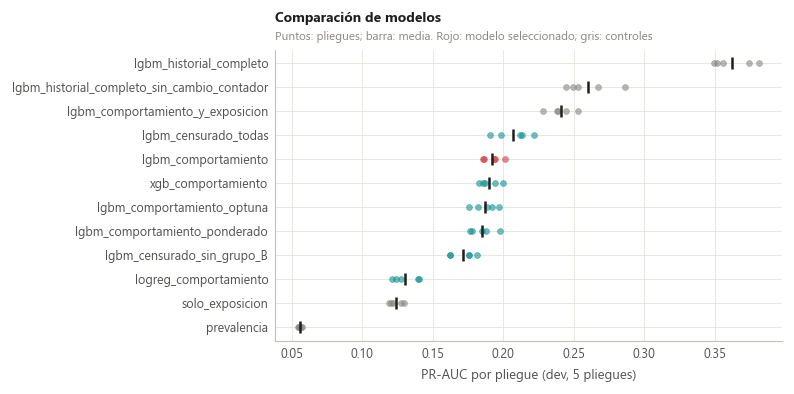

In [17]:
fig, ax = plt.subplots(figsize=fg.FIGSIZE_WIDE)
orden_fig = tabla_cv.sort_values("pr_auc_media").index
for i, m in enumerate(orden_fig):
    valores = RESULTADOS[m].por_pliegue["pr_auc"]
    es_control = "exposicion" in m or "historial_completo" in m or m == "prevalencia"
    color = fg.COLOR_FRAUD if m == MODELO_FINAL else (fg.INK_MUTED if es_control else fg.COLOR_NEUTRAL)
    ax.scatter(valores, [i] * len(valores), s=18, color=color, alpha=0.6, zorder=3)
    ax.scatter([valores.mean()], [i], s=70, marker="|", color=fg.INK, zorder=4)
ax.set_yticks(range(len(orden_fig)), orden_fig)
ax.set_xlabel("PR-AUC por pliegue (dev, 5 pliegues)")
fg.set_title(ax, "Comparación de modelos", "Puntos: pliegues; barra: media. Rojo: modelo seleccionado; gris: controles")
fig.tight_layout()
fg.save_figure(fig, REPORTS_FIGURES_DIR / "fig_model_comparacion_pr_auc.png")

## 9. Controles de exposición

Cuatro preguntas, todas con predicciones fuera de pliegue:

- ¿Cuánto se correlaciona la puntuación de cada modelo con el número de facturas del
  cliente? Un modelo que solo ordenara por exposición tendría una correlación alta.
- ¿Qué desempeño tiene cada modelo **dentro** de cada quintil de longitud de historial?
  Dentro de un quintil la exposición está aproximadamente controlada. Se usa ROC-AUC,
  que no depende de la prevalencia, porque esta cambia de un quintil a otro.
- ¿Qué desempeño hay en la población activa (clientes con facturas desde 2005)?
- ¿Qué desempeño hay dentro de los grupos con y sin evento de equipo o de contrato?

In [18]:
hist = dev["hist_n_facturas_total"].to_numpy()
# Los cortes se fijan en dev y se aplican igual en dev y en el holdout.
cortes_quintil = np.quantile(hist, [0.2, 0.4, 0.6, 0.8])
quintil_dev = np.digitize(hist, cortes_quintil, right=True) + 1
MODELOS_CONTROL = ["solo_exposicion", MODELO_FINAL, "lgbm_comportamiento_y_exposicion", "lgbm_historial_completo"]


def por_subgrupo(y, preds: dict[str, np.ndarray], grupos: np.ndarray, nombre_grupo: str) -> pd.DataFrame:
    filas = []
    for g in pd.unique(grupos):
        mask = grupos == g
        for m, p in preds.items():
            filas.append({nombre_grupo: g, "modelo": m, "clientes": int(mask.sum()),
                          "positivos": int(y[mask].sum()), "prevalencia": y[mask].mean(),
                          "roc_auc": roc_auc_score(y[mask], p[mask]),
                          "pr_auc": average_precision_score(y[mask], p[mask])})
    return pd.DataFrame(filas).sort_values([nombre_grupo, "modelo"])


correlacion_longitud = pd.Series(
    {m: spearmanr(preds_oof[m], hist).statistic for m in MODELOS_CONTROL}, name="spearman_con_n_facturas"
)
display(correlacion_longitud.round(3).to_frame())

por_quintil = por_subgrupo(y_dev, {m: preds_oof[m] for m in MODELOS_CONTROL}, quintil_dev, "quintil_historial")
display(por_quintil.pivot(index="quintil_historial", columns="modelo", values="roc_auc").round(3))

activos = dev["exp_sin_facturas_desde_2005"].to_numpy() == 0
metricas_activos = pd.DataFrame(
    {m: metricas(y_dev[activos], preds_oof[m][activos]) for m in MODELOS_CONTROL + ["logreg_comportamiento"]}
).T[["pr_auc", "roc_auc", "prevalencia"]]
display(metricas_activos.round(4))

grupo_evento_dev = np.where(con_evento_dev, "con_evento", "sin_evento")
por_evento = por_subgrupo(y_dev, {m: preds_oof[m] for m in MODELOS_CONTROL}, grupo_evento_dev, "evento_equipo")
display(por_evento.pivot(index="evento_equipo", columns="modelo", values="roc_auc").round(3))
display(por_evento.pivot(index="evento_equipo", columns="modelo", values="pr_auc").round(3))

por_quintil.to_csv(REPORTS_TABLES_DIR / "modeling_dev_por_quintil_historial.csv", index=False)
por_evento.to_csv(REPORTS_TABLES_DIR / "modeling_dev_por_evento_equipo.csv", index=False)
metricas_activos.to_csv(REPORTS_TABLES_DIR / "modeling_dev_clientes_activos.csv")

,spearman_con_n_facturas
solo_exposicion,0.688
lgbm_comportamiento,0.420
lgbm_comportamiento_y_exposicion,0.602
lgbm_historial_completo,0.529


modelo,lgbm_comportamiento,lgbm_comportamiento_y_exposicion,lgbm_historial_completo,solo_exposicion
quintil_historial,,,,
1,0.775,0.887,0.836,0.868
2,0.723,0.842,0.865,0.765
3,0.707,0.765,0.856,0.658
4,0.724,0.765,0.843,0.627
5,0.751,0.773,0.847,0.632


,pr_auc,roc_auc,prevalencia
solo_exposicion,0.1225,0.7154,0.0589
lgbm_comportamiento,0.1905,0.7541,0.0589
lgbm_comportamiento_y_exposicion,0.2399,0.8101,0.0589
lgbm_historial_completo,0.3614,0.8644,0.0589
logreg_comportamiento,0.1290,0.7039,0.0589


modelo,lgbm_comportamiento,lgbm_comportamiento_y_exposicion,lgbm_historial_completo,solo_exposicion
evento_equipo,,,,
con_evento,0.687,0.696,0.771,0.631
sin_evento,0.778,0.798,0.802,0.714


modelo,lgbm_comportamiento,lgbm_comportamiento_y_exposicion,lgbm_historial_completo,solo_exposicion
evento_equipo,,,,
con_evento,0.342,0.346,0.447,0.259
sin_evento,0.098,0.106,0.127,0.048


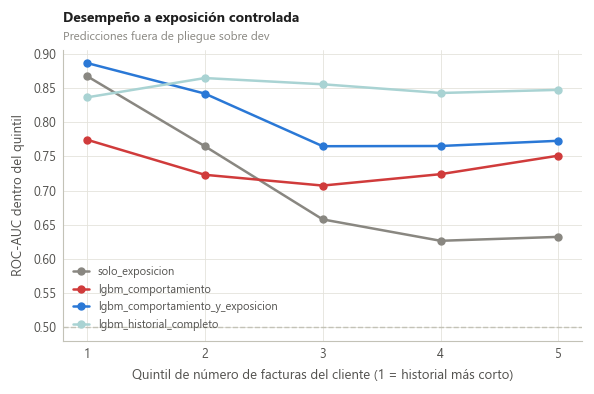

In [19]:
fig, ax = plt.subplots(figsize=fg.FIGSIZE_DEFAULT)
colores = {"solo_exposicion": fg.INK_MUTED, MODELO_FINAL: fg.COLOR_FRAUD,
           "lgbm_comportamiento_y_exposicion": fg.COLOR_NO_FRAUD, "lgbm_historial_completo": fg.COLOR_NEUTRAL_LIGHT}
pivote = por_quintil.pivot(index="quintil_historial", columns="modelo", values="roc_auc")
for m in MODELOS_CONTROL:
    ax.plot(pivote.index, pivote[m], marker="o", color=colores[m], label=m)
ax.axhline(0.5, color=fg.COLOR_AXIS, lw=1, ls="--")
ax.set_xticks([1, 2, 3, 4, 5])
ax.set_xlabel("Quintil de número de facturas del cliente (1 = historial más corto)")
ax.set_ylabel("ROC-AUC dentro del quintil")
ax.legend(frameon=False, fontsize=8)
fg.set_title(ax, "Desempeño a exposición controlada", "Predicciones fuera de pliegue sobre dev")
fig.tight_layout()
fg.save_figure(fig, REPORTS_FIGURES_DIR / "fig_model_quintiles_historial.png")

## 10. Estabilidad frente a la partición

El esquema de pliegues con semilla permite repetir la validación con otro reparto de
clientes. La dispersión entre semillas mide cuánto de la cifra de CV se debe a la
partición concreta.

In [20]:
espec_final = RESULTADOS[MODELO_FINAL].espec
filas_semillas = []
for semilla in SEMILLAS_REPETICION:
    folds_s = list(stratified_grouped_kfold_splits(dev, n_splits=N_FOLDS, seed=semilla))
    res = RESULTADOS[MODELO_FINAL] if semilla == SEED else validar(espec_final, dev, folds_s, semilla=semilla)
    filas_semillas.append({"semilla": semilla, "pr_auc_media": res.por_pliegue["pr_auc"].mean(),
                           "pr_auc_desv_pliegues": res.por_pliegue["pr_auc"].std(ddof=1),
                           "roc_auc_media": res.por_pliegue["roc_auc"].mean()})
estabilidad = pd.DataFrame(filas_semillas).set_index("semilla")
display(estabilidad.round(4))
estabilidad.to_csv(REPORTS_TABLES_DIR / "modeling_estabilidad_semillas.csv")

,pr_auc_media,pr_auc_desv_pliegues,roc_auc_media
semilla,,,
42,0.1921,0.0065,0.7683
7,0.1884,0.0108,0.7639
2026,0.1888,0.0069,0.7672


## 11. Modelo final e interpretabilidad

El modelo seleccionado se reentrena con todo `dev` (la parada temprana sigue saliendo de
un 10 % interno). La interpretabilidad usa los valores SHAP exactos de árbol que calcula el
propio modelo (`pred_contrib`), sobre una muestra de 20.000 clientes de `dev`; no se mira
el holdout. Esos clientes forman parte del entrenamiento del modelo final, así que los
valores describen qué variables usa el modelo, no cuánto rinde fuera de muestra.

In [21]:
modelo_final = ModeloFraude(espec_final).fit(dev, y_dev)
MODELS_DIR.joinpath(f"modelo_final_{FECHA}.txt").write_text(
    modelo_final.estimador_.booster_.model_to_string() if espec_final.algoritmo == "lgbm" else "", encoding="utf-8"
)
print("iteraciones del modelo final:", modelo_final.n_iter_)

muestra_shap = dev.sample(20_000, random_state=SEED)
X_shap = modelo_final.transformar(muestra_shap)
if espec_final.algoritmo == "lgbm":
    contrib = modelo_final.estimador_.booster_.predict(X_shap, pred_contrib=True)[:, :-1]
elif espec_final.algoritmo == "xgb":
    import xgboost as xgb
    contrib = modelo_final.estimador_.get_booster().predict(
        xgb.DMatrix(X_shap, enable_categorical=True), pred_contribs=True)[:, :-1]
else:
    raise NotImplementedError("la interpretación por SHAP se implementa para modelos de árboles")
valores_shap = pd.DataFrame(contrib, columns=X_shap.columns, index=X_shap.index)

FAMILIA_COMPLETA = FAMILIA.copy()
importancia = valores_shap.abs().mean().sort_values(ascending=False).rename("media_abs_shap").to_frame()
importancia["familia"] = importancia.index.map(FAMILIA_COMPLETA)
importancia["participacion"] = importancia["media_abs_shap"] / importancia["media_abs_shap"].sum()
importancia.to_csv(REPORTS_TABLES_DIR / "modeling_importancia_shap.csv")
display(importancia.head(20).round(4))
importancia_familia = importancia.groupby("familia")["participacion"].sum().sort_values(ascending=False)
display(importancia_familia.round(3).to_frame())

iteraciones del modelo final: 746


,media_abs_shap,familia,participacion
inv_share_codigo_contador_207,0.3692,tarifa_contador,0.1236
inv_elec_log_cons_p90,0.2503,consumo,0.0838
cli_region,0.1587,cliente,0.0531
inv_elec_pendiente_log_cons_anual,0.1281,dinamica,0.0429
inv_share_codigo_contador_203,0.1280,tarifa_contador,0.0428
cli_disrict,0.1146,cliente,0.0384
inv_elec_share_caidas_fuertes,0.1112,dinamica,0.0372
inv_share_tarifa_11,0.0968,tarifa_contador,0.0324
inv_share_facturas_gas,0.0953,tarifa_contador,0.0319
inv_elec_share_subidas_fuertes,0.0938,dinamica,0.0314


,participacion
familia,
tarifa_contador,0.312
consumo,0.196
dinamica,0.182
lectura,0.139
cliente,0.096
relativa_pares,0.074


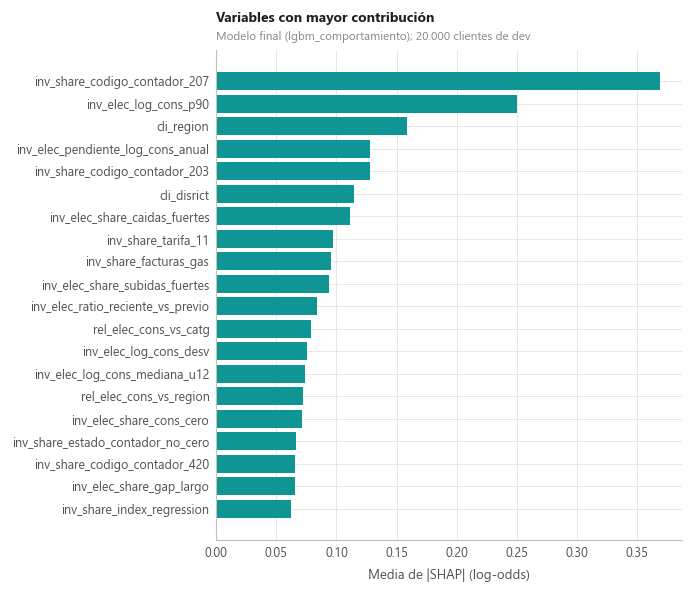

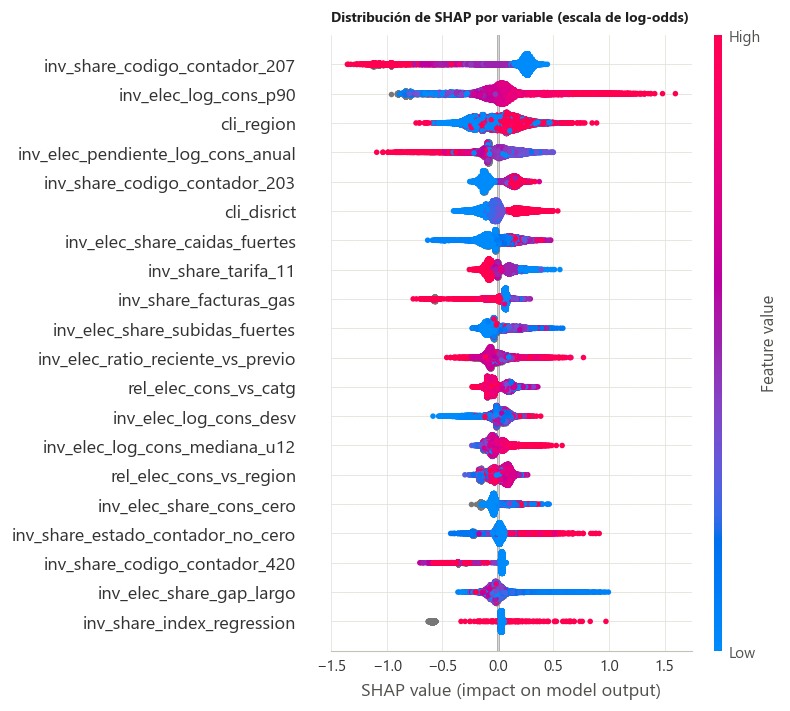

In [22]:
top = importancia.head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(7.0, 6.0))
ax.barh(top.index, top["media_abs_shap"], color=fg.COLOR_NEUTRAL)
ax.set_xlabel("Media de |SHAP| (log-odds)")
fg.set_title(ax, "Variables con mayor contribución", f"Modelo final ({MODELO_FINAL}); 20.000 clientes de dev")
fig.tight_layout()
fg.save_figure(fig, REPORTS_FIGURES_DIR / "fig_model_shap_importancia.png")

X_display = X_shap[top.index[::-1]].copy()
for c in X_display.columns:
    if isinstance(X_display[c].dtype, pd.CategoricalDtype):
        X_display[c] = X_display[c].cat.codes.astype(float)
plt.figure()
shap.summary_plot(valores_shap[top.index[::-1]].to_numpy(), X_display, show=False, max_display=20, plot_size=(8.0, 7.0))
fig = plt.gcf()
fig.axes[0].set_title("Distribución de SHAP por variable (escala de log-odds)", loc="left", fontsize=10)
fg.save_figure(fig, REPORTS_FIGURES_DIR / "fig_model_shap_beeswarm.png")

## 12. Evaluación única sobre el holdout sellado

Esta sección solo se ejecuta con `EVALUAR_HOLDOUT = True`, una vez elegido el modelo. Se
reportan el modelo final y, como contexto, la línea base de solo exposición, el modelo con
exposición, el modelo sobre el historial completo y, como control de sensibilidad, el
modelo sin el grupo B de variables con deriva de calendario, todos entrenados también sobre
`dev`; ninguno de esos números interviene ya en la selección. Cada cifra global va
acompañada de la del grupo sin evento de equipo o de contrato. Los intervalos son bootstrap por cliente.

,pr_auc,pr_auc_ic95_lo,pr_auc_ic95_hi,roc_auc,brier,prevalencia
modelo,,,,,,
lgbm_comportamiento,0.1915,0.1745,0.2108,0.7615,0.0490,0.0558
solo_exposicion,0.1316,0.1217,0.1437,0.7452,0.0506,0.0558
lgbm_comportamiento_y_exposicion,0.2426,0.2235,0.2645,0.8179,0.0472,0.0558
lgbm_historial_completo,0.3814,0.3589,0.4071,0.8789,0.0418,0.0558
lgbm_censurado_sin_grupo_B,0.1740,0.1582,0.1920,0.7425,0.0497,0.0558


,fraccion,k,precision,recall,techo_recall,lift
0,0.005,135,0.4074,0.0364,0.0892,7.2970
1,0.010,271,0.4354,0.0780,0.1791,7.7988
2,0.020,542,0.3542,0.1269,0.3582,6.3448
3,0.050,1355,0.2598,0.2327,0.8956,4.6528
4,0.100,2710,0.1923,0.3443,1.0000,3.4434


modelo,lgbm_censurado_sin_grupo_B,lgbm_comportamiento,lgbm_comportamiento_y_exposicion,lgbm_historial_completo,solo_exposicion
quintil_historial,,,,,
1,0.782,0.798,0.903,0.872,0.909
2,0.631,0.676,0.807,0.856,0.732
3,0.666,0.699,0.763,0.862,0.663
4,0.699,0.710,0.754,0.845,0.663
5,0.737,0.755,0.779,0.859,0.644


,pr_auc,roc_auc,prevalencia
lgbm_comportamiento,0.1915,0.7474,0.0589
solo_exposicion,0.1316,0.7301,0.0589
lgbm_comportamiento_y_exposicion,0.2426,0.8071,0.0589
lgbm_historial_completo,0.3814,0.8718,0.0589
lgbm_censurado_sin_grupo_B,0.1740,0.7272,0.0589


modelo,lgbm_censurado_sin_grupo_B,lgbm_comportamiento,lgbm_comportamiento_y_exposicion,lgbm_historial_completo,solo_exposicion
evento_equipo,,,,,
con_evento,0.675,0.689,0.693,0.781,0.633
sin_evento,0.753,0.758,0.791,0.804,0.733


modelo,lgbm_censurado_sin_grupo_B,lgbm_comportamiento,lgbm_comportamiento_y_exposicion,lgbm_historial_completo,solo_exposicion
evento_equipo,,,,,
con_evento,0.348,0.365,0.361,0.473,0.270
sin_evento,0.080,0.086,0.095,0.114,0.048


,distrito,modelo,clientes,positivos,prevalencia,roc_auc,pr_auc
3,60,lgbm_comportamiento,6462,223,0.0345,0.7397,0.1058
0,62,lgbm_comportamiento,8017,401,0.0500,0.7695,0.1681
2,63,lgbm_comportamiento,5780,385,0.0666,0.7692,0.2546
1,69,lgbm_comportamiento,6840,504,0.0737,0.7303,0.1984


,prob_media,tasa_observada,clientes
decil,,,
0,0.0024,0.0022,2710
1,0.0106,0.0114,2710
2,0.0172,0.0207,2710
3,0.0240,0.0258,2710
4,0.0314,0.0380,2710
5,0.0402,0.0425,2709
6,0.0517,0.0517,2710
7,0.0682,0.0672,2710
8,0.0969,0.1066,2710


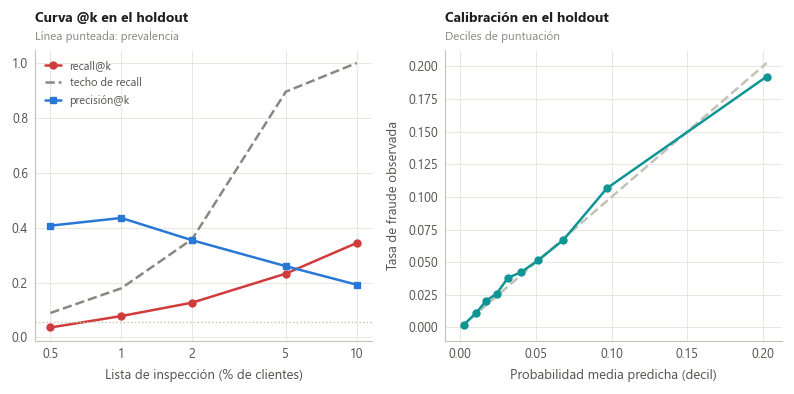

In [23]:
resultado_holdout = None
if EVALUAR_HOLDOUT:
    y_hold = holdout["target"].to_numpy()
    preds_hold = {MODELO_FINAL: modelo_final.predict_proba(holdout)}
    holdout_completo = tabla_train_completo.loc[tabla_train_completo["is_holdout"]].reset_index(drop=True)
    for m, d_tr, d_ho in [("solo_exposicion", dev, holdout),
                          ("lgbm_comportamiento_y_exposicion", dev, holdout),
                          ("lgbm_historial_completo", dev_completo, holdout_completo),
                          ("lgbm_censurado_sin_grupo_B", dev, holdout)]:
        preds_hold[m] = ModeloFraude(RESULTADOS[m].espec).fit(d_tr, y_dev).predict_proba(d_ho)
    ic_holdout, replicas_hold = bootstrap_pareado(y_hold, preds_hold, referencia=MODELO_FINAL)

    filas_hold = []
    for m, p in preds_hold.items():
        filas_hold.append({"modelo": m, **metricas(y_hold, p)})
    resultado_holdout = pd.DataFrame(filas_hold).set_index("modelo").join(ic_holdout.drop(columns="pr_auc"))
    roc_rep = []
    rng = np.random.default_rng(SEED)
    for _ in range(N_BOOTSTRAP):
        idx = rng.integers(0, len(y_hold), len(y_hold))
        roc_rep.append(roc_auc_score(y_hold[idx], preds_hold[MODELO_FINAL][idx]))
    resultado_holdout.loc[MODELO_FINAL, "roc_auc_ic95_lo"] = np.quantile(roc_rep, 0.025)
    resultado_holdout.loc[MODELO_FINAL, "roc_auc_ic95_hi"] = np.quantile(roc_rep, 0.975)
    resultado_holdout.to_csv(REPORTS_TABLES_DIR / "modeling_holdout_metricas.csv")
    display(resultado_holdout[["pr_auc", "pr_auc_ic95_lo", "pr_auc_ic95_hi", "roc_auc", "brier", "prevalencia"]].round(4))

    curva_k = pd.DataFrame([
        {"fraccion": f, "k": int(round(f * len(y_hold))),
         "precision": metricas(y_hold, preds_hold[MODELO_FINAL])[f"precision@{f * 100:g}%"],
         "recall": metricas(y_hold, preds_hold[MODELO_FINAL])[f"recall@{f * 100:g}%"],
         "techo_recall": metricas(y_hold, preds_hold[MODELO_FINAL])[f"techo_recall@{f * 100:g}%"],
         "lift": metricas(y_hold, preds_hold[MODELO_FINAL])[f"lift@{f * 100:g}%"]}
        for f in FRACCIONES_K
    ])
    curva_k.to_csv(REPORTS_TABLES_DIR / "modeling_holdout_curva_k.csv", index=False)
    display(curva_k.round(4))

    quintil_hold = np.digitize(holdout["hist_n_facturas_total"].to_numpy(), cortes_quintil, right=True) + 1
    hold_quintil = por_subgrupo(y_hold, preds_hold, quintil_hold, "quintil_historial")
    hold_quintil.to_csv(REPORTS_TABLES_DIR / "modeling_holdout_por_quintil_historial.csv", index=False)
    display(hold_quintil.pivot(index="quintil_historial", columns="modelo", values="roc_auc").round(3))

    activos_hold = holdout["exp_sin_facturas_desde_2005"].to_numpy() == 0
    hold_activos = pd.DataFrame({m: metricas(y_hold[activos_hold], p[activos_hold]) for m, p in preds_hold.items()}).T
    hold_activos[["pr_auc", "roc_auc", "prevalencia"]].to_csv(REPORTS_TABLES_DIR / "modeling_holdout_clientes_activos.csv")
    display(hold_activos[["pr_auc", "roc_auc", "prevalencia"]].round(4))

    grupo_evento_hold = np.where(holdout["hist_con_evento_equipo"].to_numpy(), "con_evento", "sin_evento")
    hold_evento = por_subgrupo(y_hold, preds_hold, grupo_evento_hold, "evento_equipo")
    hold_evento.to_csv(REPORTS_TABLES_DIR / "modeling_holdout_por_evento_equipo.csv", index=False)
    display(hold_evento.pivot(index="evento_equipo", columns="modelo", values="roc_auc").round(3))
    display(hold_evento.pivot(index="evento_equipo", columns="modelo", values="pr_auc").round(3))

    hold_catg = por_subgrupo(y_hold, {MODELO_FINAL: preds_hold[MODELO_FINAL]},
                             holdout["cli_disrict"].astype(int).to_numpy(), "distrito")
    hold_catg.to_csv(REPORTS_TABLES_DIR / "modeling_holdout_por_distrito.csv", index=False)
    display(hold_catg.round(4))

    p_final = preds_hold[MODELO_FINAL]
    deciles = pd.qcut(pd.Series(p_final).rank(method="first"), 10, labels=False)
    calibracion = pd.DataFrame({"p": p_final, "y": y_hold, "decil": deciles}).groupby("decil").agg(
        prob_media=("p", "mean"), tasa_observada=("y", "mean"), clientes=("y", "size"))
    calibracion.to_csv(REPORTS_TABLES_DIR / "modeling_holdout_calibracion.csv")
    display(calibracion.round(4))

    fig, axes = plt.subplots(1, 2, figsize=fg.FIGSIZE_WIDE)
    ax = axes[0]
    pct = [f * 100 for f in FRACCIONES_K]
    ax.plot(pct, curva_k["recall"], marker="o", color=fg.COLOR_FRAUD, label="recall@k")
    ax.plot(pct, curva_k["techo_recall"], marker="", ls="--", color=fg.INK_MUTED, label="techo de recall")
    ax.plot(pct, curva_k["precision"], marker="s", color=fg.COLOR_NO_FRAUD, label="precisión@k")
    ax.axhline(y_hold.mean(), color=fg.COLOR_AXIS, lw=1, ls=":")
    ax.set_xlabel("Lista de inspección (% de clientes)")
    ax.set_xscale("log")
    ax.set_xticks(pct, [f"{v:g}" for v in pct])
    ax.legend(frameon=False, fontsize=8)
    fg.set_title(ax, "Curva @k en el holdout", "Línea punteada: prevalencia")
    ax = axes[1]
    ax.plot([0, calibracion["prob_media"].max()], [0, calibracion["prob_media"].max()], color=fg.COLOR_AXIS, ls="--")
    ax.plot(calibracion["prob_media"], calibracion["tasa_observada"], marker="o", color=fg.COLOR_NEUTRAL)
    ax.set_xlabel("Probabilidad media predicha (decil)")
    ax.set_ylabel("Tasa de fraude observada")
    fg.set_title(ax, "Calibración en el holdout", "Deciles de puntuación")
    fig.tight_layout()
    fg.save_figure(fig, REPORTS_FIGURES_DIR / "fig_model_holdout.png")
else:
    print("Holdout sellado: sin evaluar (EVALUAR_HOLDOUT = False).")

## 13. Exportación

Las cifras de esta corrida quedan en `reports/tables/` y `reports/metrics/`. Las
conclusiones se componen a partir de esas mismas tablas, igual que el resumen en Markdown
(`reports/MODELADO.md`), para que ningún número del texto se escriba a mano.

In [24]:
def tabla_md(df: pd.DataFrame, decimales: int = 4) -> str:
    df = df.round(decimales).reset_index()
    cabecera = "| " + " | ".join(map(str, df.columns)) + " |"
    separador = "|" + "---|" * len(df.columns)
    filas = ["| " + " | ".join("" if pd.isna(v) else str(v) for v in fila) + " |"
             for fila in df.itertuples(index=False)]
    return "\n".join([cabecera, separador, *filas])


def pct(x: float) -> str:
    return f"{100 * x:.1f} %".replace(".", ",")


def num(x: float, d: int = 3) -> str:
    return f"{x:.{d}f}".replace(".", ",")


final = tabla_cv.loc[MODELO_FINAL]
roc_evento = por_evento.pivot(index="evento_equipo", columns="modelo", values="roc_auc")
roc_quintil = por_quintil.pivot(index="quintil_historial", columns="modelo", values="roc_auc")[MODELO_FINAL]
mitades_c = verificacion_mitades.set_index(["representacion", "variables"]).loc["historial_censurado"]
mitades_f = verificacion_mitades.set_index(["representacion", "variables"]).loc["historial_completo"]
conclusiones = [
    f"El modelo seleccionado, `{MODELO_FINAL}`, obtiene en validación cruzada sobre dev un PR-AUC de "
    f"{num(final['pr_auc_media'])} (desviación entre pliegues {num(final['pr_auc_desv'])}) y un ROC-AUC de "
    f"{num(final['roc_auc_media'])}. La prevalencia constante da {num(tabla_cv.loc['prevalencia', 'pr_auc_media'])} "
    f"y la línea base de solo exposición {num(tabla_cv.loc['solo_exposicion', 'pr_auc_media'])}. "
    f"Entre semillas de partición el PR-AUC medio va de {num(estabilidad['pr_auc_media'].min())} a "
    f"{num(estabilidad['pr_auc_media'].max())}.",
    f"Dentro del grupo sin eventos de equipo o de contrato, donde no hay corte que delatar, el PR-AUC es "
    f"{num(por_evento.pivot(index='evento_equipo', columns='modelo', values='pr_auc').loc['sin_evento', MODELO_FINAL])} "
    f"(prevalencia {pct(y_dev[~con_evento_dev].mean())}) y el ROC-AUC "
    f"{num(roc_evento.loc['sin_evento', MODELO_FINAL])} frente a {num(roc_evento.loc['sin_evento', 'solo_exposicion'])} "
    f"de la línea base de solo exposición. Dentro de los quintiles de longitud del historial va de "
    f"{num(roc_quintil.min())} a {num(roc_quintil.max())}.",
    f"El modelo con historial completo llega a {num(tabla_cv.loc['lgbm_historial_completo', 'pr_auc_media'])} de PR-AUC, "
    f"pero con esa representación la segunda mitad del historial rinde {num(mitades_f.loc['segunda_mitad', 'pr_auc_media'])} "
    f"y la primera {num(mitades_f.loc['primera_mitad', 'pr_auc_media'])}; con el historial censurado la brecha baja a "
    f"{num(mitades_c.loc['segunda_mitad', 'pr_auc_media'] - mitades_c.loc['primera_mitad', 'pr_auc_media'])}. "
    "Esa diferencia de desempeño es, en buena parte, huella de la inspección y no capacidad de anticipar el fraude.",
]
if resultado_holdout is not None:
    h = resultado_holdout.loc[MODELO_FINAL]
    k1 = curva_k.set_index("fraccion").loc[0.01]
    conclusiones.append(
        f"En el holdout sellado, evaluado una sola vez, el modelo obtiene un PR-AUC de {num(h['pr_auc'])} "
        f"(IC 95 % [{num(h['pr_auc_ic95_lo'])}, {num(h['pr_auc_ic95_hi'])}]) y un ROC-AUC de {num(h['roc_auc'])} "
        f"(IC 95 % [{num(h['roc_auc_ic95_lo'])}, {num(h['roc_auc_ic95_hi'])}]). En una lista del 1 % de los clientes "
        f"({int(k1['k'])}) la precisión es {pct(k1['precision'])}, {num(k1['lift'], 1)} veces la prevalencia, con un "
        f"recall de {pct(k1['recall'])} sobre un techo de {pct(k1['techo_recall'])}."
    )
    he = hold_evento.set_index(["evento_equipo", "modelo"])
    conclusiones.append(
        f"Dentro del grupo sin eventos del holdout (prevalencia "
        f"{pct(he.loc[('sin_evento', MODELO_FINAL), 'prevalencia'])}), el PR-AUC es "
        f"{num(he.loc[('sin_evento', MODELO_FINAL), 'pr_auc'])} y el ROC-AUC "
        f"{num(he.loc[('sin_evento', MODELO_FINAL), 'roc_auc'])}. El control sin el grupo B obtiene "
        f"{num(resultado_holdout.loc['lgbm_censurado_sin_grupo_B', 'pr_auc'])} de PR-AUC global y "
        f"{num(he.loc[('sin_evento', 'lgbm_censurado_sin_grupo_B'), 'roc_auc'])} de ROC-AUC sin evento."
    )
for parrafo in conclusiones:
    print(parrafo, end="\n\n")

diccionario.assign(
    descartada_por_redundancia=diccionario["column"].isin(descartadas),
    en_modelo_principal=diccionario["column"].isin(VARS_COMPORTAMIENTO)
    | (diccionario["familia"].eq("relativa_pares") & espec_final.relativas),
).to_csv(REPORTS_TABLES_DIR / "feature_dictionary.csv", index=False)

lineas = [
    "# Resultados del modelado",
    "",
    f"Generado por `notebooks/02_modelado.ipynb` el {date.today().isoformat()}. "
    "No editar a mano: las cifras salen de `reports/tables/` y `reports/metrics/`.",
    "",
    f"- Clientes en dev: {len(dev):,} ({int(y_dev.sum()):,} positivos); holdout: {len(holdout):,}.",
    f"- Variables de comportamiento: {len(VARS_COMPORTAMIENTO)}; descartadas por redundancia: {descartadas or 'ninguna'}.",
    f"- ROC-AUC adversarial train frente a test: {auc_adversarial:.4f}.",
    f"- Hiperparámetros de Optuna: {json.dumps({k: round(v, 4) if isinstance(v, float) else v for k, v in PARAMS_OPTUNA.items()})}.",
    f"- Modelo seleccionado: `{MODELO_FINAL}` (mejor PR-AUC fuera de pliegue: `{mejor_oof}`).",
    "",
    "## Conclusiones",
    "",
    *[parrafo + "\n" for parrafo in conclusiones],
    "## Validación cruzada en dev",
    "",
    tabla_md(tabla_comparacion[["pr_auc_media", "pr_auc_desv", "roc_auc_media", "pr_auc_oof",
                                f"delta_vs_{mejor_oof}", "delta_ic95_lo", "delta_ic95_hi", "lift@1%", "recall@5%"]]),
    "",
    "## Controles de exposición",
    "",
    tabla_md(correlacion_longitud.to_frame(), 3),
    "",
    tabla_md(por_quintil.pivot(index="quintil_historial", columns="modelo", values="roc_auc"), 3),
    "",
    tabla_md(metricas_activos),
    "",
    "## Huellas de la inspección",
    "",
    tabla_md(tiempos_eventos.T, 3),
    "",
    tabla_md(tiempos_fenomenos.T, 3),
    "",
    tabla_md(verificacion_mitades.set_index(["representacion", "variables"])),
    "",
    tabla_md(diagnostico_calendario.T),
    "",
    "## Desempeño por evento de equipo o de contrato (dev)",
    "",
    tabla_md(por_evento.pivot(index="evento_equipo", columns="modelo", values="roc_auc"), 3),
    "",
    "## Estabilidad frente a la semilla de partición",
    "",
    tabla_md(estabilidad),
    "",
    "## Importancia por familia (SHAP)",
    "",
    tabla_md(importancia_familia.to_frame(), 3),
]
if resultado_holdout is not None:
    lineas += [
        "",
        "## Holdout sellado (evaluación única)",
        "",
        tabla_md(resultado_holdout[["pr_auc", "pr_auc_ic95_lo", "pr_auc_ic95_hi", "roc_auc", "brier"]]),
        "",
        tabla_md(curva_k.set_index("fraccion")),
        "",
        tabla_md(hold_evento.pivot(index="evento_equipo", columns="modelo", values="roc_auc"), 3),
        "",
        tabla_md(hold_quintil.pivot(index="quintil_historial", columns="modelo", values="roc_auc"), 3),
        "",
        tabla_md(calibracion),
    ]
(REPORTS_DIR / "MODELADO.md").write_text("\n".join(lineas) + "\n", encoding="utf-8")
print(f"tiempo total: {(time.time() - T0) / 60:.1f} min")

El modelo seleccionado, `lgbm_comportamiento`, obtiene en validación cruzada sobre dev un PR-AUC de 0,192 (desviación entre pliegues 0,006) y un ROC-AUC de 0,768. La prevalencia constante da 0,056 y la línea base de solo exposición 0,124. Entre semillas de partición el PR-AUC medio va de 0,188 a 0,192.

Dentro del grupo sin eventos de equipo o de contrato, donde no hay corte que delatar, el PR-AUC es 0,098 (prevalencia 2,2 %) y el ROC-AUC 0,778 frente a 0,714 de la línea base de solo exposición. Dentro de los quintiles de longitud del historial va de 0,707 a 0,775.

El modelo con historial completo llega a 0,363 de PR-AUC, pero con esa representación la segunda mitad del historial rinde 0,396 y la primera 0,182; con el historial censurado la brecha baja a 0,031. Esa diferencia de desempeño es, en buena parte, huella de la inspección y no capacidad de anticipar el fraude.

En el holdout sellado, evaluado una sola vez, el modelo obtiene un PR-AUC de 0,191 (IC 95 % [0,174, 0,211]) y un RO